# Urban Traffic Flow, Congestion Management & Mobility Optimization

## 1. Introduction

### Business Problem

Bangalore has traffic congestion, increasing travel time, uneven road utilization, and pressure on existing infrastructure.

In this project, I will analyze historical traffic data to understand traffic flow, congestion patterns, bottlenecks, and overall mobility performance.

### Business Objective

The main objectives of this project are to identify:

- When congestion is highest
- Which locations have higher congestion
- Factors related to traffic congestion
- Major traffic bottlenecks
- High-risk congestion periods
- Possible ways to improve urban mobility

### Analytical Approach

The analysis will follow these steps:

Data Understanding → Data Cleaning → Data Validation
→ Feature Engineering → KPI Analysis → Traffic Analysis
→ Advanced Analytics → Visualization → Dashboard → Strategy

### Tools Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Plotly
- Jupyter Notebook

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


## 2. Data Loading

In [2]:
df = pd.read_csv("../data/raw/Banglore_traffic_Dataset.csv")

In [3]:
df.columns = df.columns.str.lower().str.replace(" ", "_")

In [4]:
df.head()

,date,area_name,road/intersection_name,traffic_volume,average_speed,travel_time_index,congestion_level,road_capacity_utilization,incident_reports,environmental_impact,public_transport_usage,traffic_signal_compliance,parking_usage,pedestrian_and_cyclist_count,weather_conditions,roadwork_and_construction_activity
0,2022-01-01,Indiranagar,100 Feet Road,50590,50.230299,1.500000,100.000000,100.000000,0,151.180,70.632330,84.044600,85.403629,111,Clear,No
1,2022-01-01,Indiranagar,CMH Road,30825,29.377125,1.500000,100.000000,100.000000,1,111.650,41.924899,91.407038,59.983689,100,Clear,No
2,2022-01-01,Whitefield,Marathahalli Bridge,7399,54.474398,1.039069,28.347994,36.396525,0,64.798,44.662384,61.375541,95.466020,189,Clear,No
3,2022-01-01,Koramangala,Sony World Junction,60874,43.817610,1.500000,100.000000,100.000000,1,171.748,32.773123,75.547092,63.567452,111,Clear,No
4,2022-01-01,Koramangala,Sarjapur Road,57292,41.116763,1.500000,100.000000,100.000000,3,164.584,35.092601,64.634762,93.155171,104,Clear,No


In [5]:
df.shape

(8936, 16)

In [6]:
df.columns.tolist()

['date',
 'area_name',
 'road/intersection_name',
 'traffic_volume',
 'average_speed',
 'travel_time_index',
 'congestion_level',
 'road_capacity_utilization',
 'incident_reports',
 'environmental_impact',
 'public_transport_usage',
 'traffic_signal_compliance',
 'parking_usage',
 'pedestrian_and_cyclist_count',
 'weather_conditions',
 'roadwork_and_construction_activity']

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8936 entries, 0 to 8935
Data columns (total 16 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   date                                8936 non-null   str    
 1   area_name                           8936 non-null   str    
 2   road/intersection_name              8936 non-null   str    
 3   traffic_volume                      8936 non-null   int64  
 4   average_speed                       8936 non-null   float64
 5   travel_time_index                   8936 non-null   float64
 6   congestion_level                    8936 non-null   float64
 7   road_capacity_utilization           8936 non-null   float64
 8   incident_reports                    8936 non-null   int64  
 9   environmental_impact                8936 non-null   float64
 10  public_transport_usage              8936 non-null   float64
 11  traffic_signal_compliance           8936 non-null   fl

In [8]:
df.describe()

,traffic_volume,average_speed,travel_time_index,congestion_level,road_capacity_utilization,incident_reports,environmental_impact,public_transport_usage,traffic_signal_compliance,parking_usage,pedestrian_and_cyclist_count
count,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000
mean,29236.048120,39.447427,1.375554,80.818041,92.029215,1.570389,108.472096,45.086651,79.950243,75.155597,114.533348
std,13001.808801,10.707244,0.165319,23.533182,16.583341,1.420047,26.003618,20.208460,11.585006,14.409394,36.812573
min,4233.000000,20.000000,1.000039,5.160279,18.739771,0.000000,58.466000,10.006853,60.003933,50.020411,66.000000
25%,19413.000000,31.775825,1.242459,64.292905,97.354990,0.000000,88.826000,27.341191,69.828270,62.545895,94.000000
50%,27600.000000,39.199368,1.500000,92.389018,100.000000,1.000000,105.200000,45.170684,79.992773,75.317610,102.000000
75%,38058.500000,46.644517,1.500000,100.000000,100.000000,2.000000,126.117000,62.426485,89.957358,87.518589,111.000000
max,72039.000000,89.790843,1.500000,100.000000,100.000000,10.000000,194.078000,79.979744,99.993652,99.995049,243.000000


In [9]:
df.isnull().sum()

date                                  0
area_name                             0
road/intersection_name                0
traffic_volume                        0
average_speed                         0
travel_time_index                     0
congestion_level                      0
road_capacity_utilization             0
incident_reports                      0
environmental_impact                  0
public_transport_usage                0
traffic_signal_compliance             0
parking_usage                         0
pedestrian_and_cyclist_count          0
weather_conditions                    0
roadwork_and_construction_activity    0
dtype: int64

## 3. Data Understanding

### Important Data Fields

| Field | Business Meaning |
|---|---|
| date | Date of the traffic observation |
| area_name | Area where the traffic was observed |
| road/intersection_name | Road or intersection being analyzed |
| traffic_volume | Traffic volume recorded at the observation |
| average_speed | Average vehicle speed |
| travel_time_index | Indicator of travel time conditions |
| congestion_level | Level of traffic congestion |
| road_capacity_utilization | Degree to which road capacity is being used |
| incident_reports | Number of reported traffic incidents |
| public_transport_usage | Public transport usage level |
| traffic_signal_compliance | Level of compliance with traffic signals |
| parking_usage | Parking usage level |
| weather_conditions | Weather condition during the observation |
| roadwork_and_construction_activity | Indicates roadwork/construction activity |
| pedestrian_and_cyclist_count | Number of pedestrians and cyclists recorded |

## 4. Data Cleaning

### 4.1 Convert Date to Datetime

The Date column is currently stored as text. It will be converted to
datetime format so that we can perform time-based analysis later.

In [10]:
df['date'] = pd.to_datetime(df['date'])
df['date'].dtype

dtype('<M8[us]')

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df['weather_conditions'].value_counts()

weather_conditions
Clear       5426
Overcast    1296
Fog          959
Rain         827
Windy        428
Name: count, dtype: int64

In [13]:
df['roadwork_and_construction_activity'].value_counts()

roadwork_and_construction_activity
No     8054
Yes     882
Name: count, dtype: int64

In [14]:
df['congestion_level'].describe()

count    8936.000000
mean       80.818041
std        23.533182
min         5.160279
25%        64.292905
50%        92.389018
75%       100.000000
max       100.000000
Name: congestion_level, dtype: float64

In [15]:
df['congestion_level'].value_counts()

congestion_level
100.000000    3884
28.347994        1
79.038823        1
78.979596        1
97.672462        1
              ... 
30.463408        1
93.969031        1
35.871483        1
72.639152        1
43.409821        1
Name: count, Length: 5053, dtype: int64

## 5. Data Validation

### 5.1 Validate Numerical Ranges

The numerical traffic measures are checked for unrealistic or out-of-range values before analysis.

In [16]:
df['congestion_level'].min(), df['congestion_level'].max()

(np.float64(5.160279008043586), np.float64(100.0))

In [17]:
df[(df['congestion_level'] < 0) | (df['congestion_level'] > 100)].shape

(0, 16)

In [18]:
df['average_speed'].min(), df['average_speed'].max()

(np.float64(20.0), np.float64(89.79084251025756))

In [19]:
df[df['average_speed'] <= 0].shape

(0, 16)

In [20]:
df.shape

(8936, 16)

In [21]:
df['congestion_level'].shape

(8936,)

In [22]:
df['congestion_level'].isnull().sum()

np.int64(0)

In [23]:
print("Traffic Volume:", df['traffic_volume'].min(), df['traffic_volume'].max())

print("Travel Time Index:", df['travel_time_index'].min(), df['travel_time_index'].max())

print("Road Capacity Utilization:", df['road_capacity_utilization'].min(), df['road_capacity_utilization'].max())

print("Incident Reports:", df['incident_reports'].min(), df['incident_reports'].max())

Traffic Volume: 4233 72039
Travel Time Index: 1.0000385482661114 1.5
Road Capacity Utilization: 18.73977149973116 100.0
Incident Reports: 0 10


In [24]:
print("Environmental Impact:", df['environmental_impact'].min(), df['environmental_impact'].max())

print("Public Transport Usage:", df['public_transport_usage'].min(), df['public_transport_usage'].max())

print("Traffic Signal Compliance:", df['traffic_signal_compliance'].min(), df['traffic_signal_compliance'].max())

print("Parking Usage:", df['parking_usage'].min(), df['parking_usage'].max())

print("Pedestrian and Cyclist Count:", df['pedestrian_and_cyclist_count'].min(), df['pedestrian_and_cyclist_count'].max())

Environmental Impact: 58.466 194.078
Public Transport Usage: 10.006853048659872 79.9797440870127
Traffic Signal Compliance: 60.003932901833785 99.99365201991688
Parking Usage: 50.020411058262646 99.9950488504616
Pedestrian and Cyclist Count: 66 243


In [25]:
print("Number of Areas:", df['area_name'].nunique())

print("Number of Roads/Intersections:", df['road/intersection_name'].nunique())

Number of Areas: 8
Number of Roads/Intersections: 16


In [26]:
print(df['area_name'].unique())

<ArrowStringArray>
[    'Indiranagar',      'Whitefield',     'Koramangala',       'M.G. Road',
       'Jayanagar',          'Hebbal',    'Yeshwanthpur', 'Electronic City']
Length: 8, dtype: str


## 6. Feature Engineering

### 6.1 Create Time-Based Features

Time-based features will be created from the Date column to support analysis of traffic and congestion patterns over time.

In [27]:
df['date']

0      2022-01-01
1      2022-01-01
2      2022-01-01
3      2022-01-01
4      2022-01-01
          ...    
8931   2024-08-09
8932   2024-08-09
8933   2024-08-09
8934   2024-08-09
8935   2024-08-09
Name: date, Length: 8936, dtype: datetime64[us]

In [28]:
df['year'] = df['date'].dt.year

In [29]:
df[['date', 'year']].head()

,date,year
0,2022-01-01,2022
1,2022-01-01,2022
2,2022-01-01,2022
3,2022-01-01,2022
4,2022-01-01,2022


In [30]:
df['month'] = df['date'].dt.month

In [31]:
df[['date', 'year', 'month']].head()

,date,year,month
0,2022-01-01,2022,1
1,2022-01-01,2022,1
2,2022-01-01,2022,1
3,2022-01-01,2022,1
4,2022-01-01,2022,1


In [32]:
df['day'] = df['date'].dt.day

In [33]:
df[['date', 'year', 'month', 'day']].head()

,date,year,month,day
0,2022-01-01,2022,1,1
1,2022-01-01,2022,1,1
2,2022-01-01,2022,1,1
3,2022-01-01,2022,1,1
4,2022-01-01,2022,1,1


In [34]:
df['day_name'] = df['date'].dt.day_name()

In [35]:
df[['date', 'year', 'month', 'day', 'day_name']].head()

,date,year,month,day,day_name
0,2022-01-01,2022,1,1,Saturday
1,2022-01-01,2022,1,1,Saturday
2,2022-01-01,2022,1,1,Saturday
3,2022-01-01,2022,1,1,Saturday
4,2022-01-01,2022,1,1,Saturday


In [36]:
df.to_csv("../data/processed/Bangalore_traffic_processed.csv", index=False)

In [37]:
import os

os.path.exists("../data/processed/Bangalore_traffic_processed.csv")

True

# 7. KPI Framework

The KPI framework defines the key performance indicators used to evaluate traffic flow, congestion, road utilization, speed, delay, and overall mobility performance.

## 7.1 Key Traffic Performance Indicators

The following KPIs will be used in the analysis:

- Average Traffic Volume
- Average Speed
- Average Congestion Level
- Road Capacity Utilization
- Average Travel Time Index
- Traffic Signal Compliance
- Public Transport Usage
- Parking Usage
- Incident Reports
- Pedestrian and Cyclist Count

In [38]:
kpis = {

    'Average Traffic Volume': df['traffic_volume'].mean(),

    'Average Speed': df['average_speed'].mean(),

    'Average Congestion Level': df['congestion_level'].mean(),

    'Average Road Capacity Utilization': df['road_capacity_utilization'].mean(),

    'Average Travel Time Index': df['travel_time_index'].mean(),

    'Average Traffic Signal Compliance': df['traffic_signal_compliance'].mean(),

    'Average Public Transport Usage': df['public_transport_usage'].mean(),

    'Average Parking Usage': df['parking_usage'].mean(),

    'Average Incident Reports': df['incident_reports'].mean(),

    'Average Pedestrian and Cyclist Count': df['pedestrian_and_cyclist_count'].mean()

}

kpi_summary = pd.Series(kpis)

kpi_summary

Average Traffic Volume                  29236.048120
Average Speed                              39.447427
Average Congestion Level                   80.818041
Average Road Capacity Utilization          92.029215
Average Travel Time Index                   1.375554
Average Traffic Signal Compliance          79.950243
Average Public Transport Usage             45.086651
Average Parking Usage                      75.155597
Average Incident Reports                    1.570389
Average Pedestrian and Cyclist Count      114.533348
dtype: float64

In [39]:
location_kpis = df.groupby('area_name').agg({

    'traffic_volume': 'mean',

    'average_speed': 'mean',

    'congestion_level': 'mean',

    'road_capacity_utilization': 'mean',

    'travel_time_index': 'mean'

})

location_kpis

,traffic_volume,average_speed,congestion_level,road_capacity_utilization,travel_time_index
area_name,,,,,
Electronic City,16346.644928,43.661789,54.454507,76.258493,1.226548
Hebbal,26533.232632,40.149855,80.087244,92.721933,1.367675
Indiranagar,32284.388372,38.644341,87.641890,95.758771,1.402299
Jayanagar,24601.329923,39.789692,76.998324,91.518924,1.356745
Koramangala,40832.253666,36.062629,93.985536,97.427255,1.468823
M.G. Road,35300.426382,37.535189,90.579670,96.554472,1.440619
Whitefield,21295.127389,42.140866,69.054661,86.877474,1.293556
Yeshwanthpur,18931.546322,43.447576,62.369634,82.395284,1.264047


### 7.2 Day-wise KPI Analysis

This analysis compares traffic performance across different days of the week using traffic volume, average speed, congestion level, road capacity utilization, and travel time index.

In [40]:
day_kpis = df.groupby('day_name').agg({

    'traffic_volume': 'mean',

    'average_speed': 'mean',

    'congestion_level': 'mean',

    'road_capacity_utilization': 'mean',

    'travel_time_index': 'mean'

})

day_kpis


,traffic_volume,average_speed,congestion_level,road_capacity_utilization,travel_time_index
day_name,,,,,
Friday,28842.780527,39.496244,80.269071,91.403584,1.370704
Monday,29510.237654,39.237495,81.416542,92.429438,1.380550
Saturday,29062.983721,39.587561,80.275185,91.824097,1.371978
Sunday,29105.277516,39.382148,81.018733,92.092559,1.378718
Thursday,29530.357600,39.469187,81.153482,92.302291,1.377331
Tuesday,28911.255157,39.548279,80.325207,91.989399,1.371290
Wednesday,29697.560821,39.411054,81.278563,92.155622,1.378356


### 7.3 Environmental and Operational KPIs

This analysis evaluates how weather conditions and roadwork activity are associated with traffic volume, speed, congestion, and road capacity utilization.

In [41]:
environment_kpis = df.groupby('weather_conditions').agg({

    'traffic_volume': 'mean',

    'average_speed': 'mean',

    'congestion_level': 'mean',

    'road_capacity_utilization': 'mean',

    'travel_time_index': 'mean'

})

environment_kpis

,traffic_volume,average_speed,congestion_level,road_capacity_utilization,travel_time_index
weather_conditions,,,,,
Clear,29166.666790,39.466786,80.723064,92.013140,1.374509
Fog,29183.318040,39.472225,81.609357,92.589356,1.377035
Overcast,29053.460648,39.428241,80.296523,91.529044,1.375389
Rain,29558.703748,39.282280,80.537699,91.828213,1.378861
Windy,30163.217290,39.523641,82.369907,92.880844,1.379582


### 7.4 Roadwork and Construction KPI

This analysis compares traffic performance between locations with and without roadwork or construction activity.

In [42]:
roadwork_kpis = df.groupby('roadwork_and_construction_activity').agg({

    'traffic_volume': 'mean',

    'average_speed': 'mean',

    'congestion_level': 'mean',

    'road_capacity_utilization': 'mean',

    'travel_time_index': 'mean'

})

roadwork_kpis

,traffic_volume,average_speed,congestion_level,road_capacity_utilization,travel_time_index
roadwork_and_construction_activity,,,,,
No,29194.610504,39.499814,80.822195,92.096049,1.375513
Yes,29614.436508,38.969050,80.780110,91.418922,1.375922


# 8. Traffic Analysis

This section analyzes traffic patterns across time, locations, road conditions, and congestion levels to identify important traffic trends and performance differences.

## 8.1 Congestion Trend by Year

This analysis compares the average congestion level across different years to identify long-term changes in traffic conditions.

In [43]:
year_congestion = df.groupby('year')['congestion_level'].mean()

year_congestion

year
2022    81.132754
2023    80.360646
2024    81.048393
Name: congestion_level, dtype: float64

## 8.2 Congestion Trend by Month

This analysis compares the average congestion level across months to identify months with relatively higher or lower congestion.

In [44]:
month_congestion = df.groupby('month')['congestion_level'].mean()

month_congestion

month
1     79.526147
2     80.751385
3     81.373568
4     81.273778
5     80.303649
6     81.116005
7     80.483730
8     81.560793
9     80.437626
10    81.448178
11    81.728129
12    80.126066
Name: congestion_level, dtype: float64

## 8.3 Congestion by Day of Week

This analysis compares the average congestion level across different days of the week to identify days with relatively higher or lower congestion.

In [45]:
day_congestion = df.groupby('day_name')['congestion_level'].mean()

day_congestion

day_name
Friday       80.269071
Monday       81.416542
Saturday     80.275185
Sunday       81.018733
Thursday     81.153482
Tuesday      80.325207
Wednesday    81.278563
Name: congestion_level, dtype: float64

## 8.4 Congestion by Area

This analysis compares the average congestion level across different areas to identify locations with relatively higher or lower congestion.

In [46]:
area_congestion = df.groupby('area_name')['congestion_level'].mean()

area_congestion

area_name
Electronic City    54.454507
Hebbal             80.087244
Indiranagar        87.641890
Jayanagar          76.998324
Koramangala        93.985536
M.G. Road          90.579670
Whitefield         69.054661
Yeshwanthpur       62.369634
Name: congestion_level, dtype: float64

## 8.5 Traffic Volume by Area

This analysis compares average traffic volume across different areas to identify locations with relatively higher or lower traffic demand.

In [47]:
area_traffic = df.groupby('area_name')['traffic_volume'].mean()

area_traffic

area_name
Electronic City    16346.644928
Hebbal             26533.232632
Indiranagar        32284.388372
Jayanagar          24601.329923
Koramangala        40832.253666
M.G. Road          35300.426382
Whitefield         21295.127389
Yeshwanthpur       18931.546322
Name: traffic_volume, dtype: float64

## 8.6 Average Speed by Area

This analysis compares average speed across different areas to identify locations with relatively higher or lower traffic speeds.

In [48]:
area_speed = df.groupby('area_name')['average_speed'].mean()

area_speed

area_name
Electronic City    43.661789
Hebbal             40.149855
Indiranagar        38.644341
Jayanagar          39.789692
Koramangala        36.062629
M.G. Road          37.535189
Whitefield         42.140866
Yeshwanthpur       43.447576
Name: average_speed, dtype: float64

## 8.7 Road Capacity Utilization by Area

This analysis compares average road capacity utilization across different areas to identify locations where road infrastructure is more heavily utilized.

In [49]:
area_capacity = df.groupby('area_name')['road_capacity_utilization'].mean()

area_capacity

area_name
Electronic City    76.258493
Hebbal             92.721933
Indiranagar        95.758771
Jayanagar          91.518924
Koramangala        97.427255
M.G. Road          96.554472
Whitefield         86.877474
Yeshwanthpur       82.395284
Name: road_capacity_utilization, dtype: float64

## 8.8 Travel Time Index by Area

This analysis compares the average Travel Time Index across different areas to identify locations where travel conditions are relatively slower.

In [50]:
area_tti = df.groupby('area_name')['travel_time_index'].mean()

area_tti

area_name
Electronic City    1.226548
Hebbal             1.367675
Indiranagar        1.402299
Jayanagar          1.356745
Koramangala        1.468823
M.G. Road          1.440619
Whitefield         1.293556
Yeshwanthpur       1.264047
Name: travel_time_index, dtype: float64

## 8.9 Traffic Volume by Year

This analysis compares average traffic volume across different years to identify changes in traffic demand over time.

In [51]:
year_traffic = df.groupby('year')['traffic_volume'].mean()

year_traffic

year
2022    29455.983937
2023    29016.188690
2024    29234.771320
Name: traffic_volume, dtype: float64

## 8.10 Traffic Volume by Month

This analysis compares average traffic volume across different months to identify periods with relatively higher or lower traffic demand.

In [52]:
month_traffic = df.groupby('month')['traffic_volume'].mean()

month_traffic

month
1     28830.116122
2     29147.926860
3     29515.959368
4     29573.885327
5     28926.727166
6     29741.802145
7     28875.460157
8     29504.121739
9     29083.165171
10    29380.753333
11    29302.754325
12    28952.187273
Name: traffic_volume, dtype: float64

## 8.11 Traffic Volume by Day of Week

This analysis compares average traffic volume across different days of the week to identify days with relatively higher or lower traffic demand.

In [53]:
day_traffic = df.groupby('day_name')['traffic_volume'].mean()

day_traffic

day_name
Friday       28842.780527
Monday       29510.237654
Saturday     29062.983721
Sunday       29105.277516
Thursday     29530.357600
Tuesday      28911.255157
Wednesday    29697.560821
Name: traffic_volume, dtype: float64

## 8.12 Traffic Volume vs Congestion

This analysis examines the relationship between traffic volume and congestion level to determine whether higher traffic volume is associated with higher congestion.

In [54]:
traffic_congestion = df[['traffic_volume', 'congestion_level']].corr()

traffic_congestion

,traffic_volume,congestion_level
traffic_volume,1.000000,0.837218
congestion_level,0.837218,1.000000


## 8.13 Average Speed vs Congestion

This analysis examines the relationship between average speed and congestion level to determine whether lower speeds are associated with higher congestion.

In [55]:
speed_congestion = df[['average_speed', 'congestion_level']].corr()

speed_congestion

,average_speed,congestion_level
average_speed,1.00000,-0.36025
congestion_level,-0.36025,1.00000


## 8.14 Road Capacity Utilization vs Congestion

This analysis examines the relationship between road capacity utilization and congestion level to determine whether higher road utilization is associated with higher congestion.

In [56]:
capacity_congestion = df[['road_capacity_utilization', 'congestion_level']].corr()

capacity_congestion

,road_capacity_utilization,congestion_level
road_capacity_utilization,1.000000,0.865025
congestion_level,0.865025,1.000000


## 8.15 Travel Time Index vs Congestion

This analysis examines the relationship between Travel Time Index and congestion level to determine whether higher travel delays are associated with higher congestion.

In [57]:
tti_congestion = df[['travel_time_index', 'congestion_level']].corr()

tti_congestion

,travel_time_index,congestion_level
travel_time_index,1.000000,0.751573
congestion_level,0.751573,1.000000


## 8.16 Traffic Volume vs Average Speed

This analysis examines the relationship between traffic volume and average speed to determine whether higher traffic volume is associated with lower traffic speed.

In [58]:
traffic_speed = df[['traffic_volume', 'average_speed']].corr()

traffic_speed

,traffic_volume,average_speed
traffic_volume,1.000000,-0.341138
average_speed,-0.341138,1.000000


## 8.17 Traffic Volume vs Road Capacity Utilization

This analysis examines the relationship between traffic volume and road capacity utilization to determine whether higher traffic volume is associated with greater road utilization.

In [59]:
traffic_capacity = df[['traffic_volume', 'road_capacity_utilization']].corr()

traffic_capacity

,traffic_volume,road_capacity_utilization
traffic_volume,1.000000,0.652898
road_capacity_utilization,0.652898,1.000000


## 8.18 Average Speed vs Travel Time Index

This analysis examines the relationship between average speed and Travel Time Index to determine whether lower speeds are associated with higher travel delays.

In [60]:
speed_tti = df[['average_speed', 'travel_time_index']].corr()

speed_tti

,average_speed,travel_time_index
average_speed,1.00000,-0.37617
travel_time_index,-0.37617,1.00000


## 8.19 Congestion by Weather Condition

This analysis compares average congestion levels across different weather conditions to identify weather conditions associated with relatively higher or lower congestion.

In [61]:
weather_congestion = df.groupby('weather_conditions')['congestion_level'].mean()

weather_congestion

weather_conditions
Clear       80.723064
Fog         81.609357
Overcast    80.296523
Rain        80.537699
Windy       82.369907
Name: congestion_level, dtype: float64

## 8.20 Congestion: Roadwork vs No Roadwork

This analysis compares average congestion levels between locations with and without roadwork or construction activity.

In [62]:
roadwork_congestion = df.groupby('roadwork_and_construction_activity')['congestion_level'].mean()

roadwork_congestion

roadwork_and_construction_activity
No     80.822195
Yes    80.780110
Name: congestion_level, dtype: float64

# 9. Advanced Analytics

This section applies advanced analytical techniques to identify important traffic patterns, high-congestion conditions, and factors associated with overall traffic performance.

## 9.1 High Congestion Records

This analysis identifies traffic records with very high congestion levels to understand the conditions associated with severe congestion.

In [63]:
high_congestion = df[df['congestion_level'] >= 90]

high_congestion.head(10)

,date,area_name,road/intersection_name,traffic_volume,average_speed,travel_time_index,congestion_level,road_capacity_utilization,incident_reports,environmental_impact,public_transport_usage,traffic_signal_compliance,parking_usage,pedestrian_and_cyclist_count,weather_conditions,roadwork_and_construction_activity,year,month,day,day_name
0,2022-01-01,Indiranagar,100 Feet Road,50590,50.230299,1.5,100.000000,100.0,0,151.180,70.632330,84.044600,85.403629,111,Clear,No,2022,1,1,Saturday
1,2022-01-01,Indiranagar,CMH Road,30825,29.377125,1.5,100.000000,100.0,1,111.650,41.924899,91.407038,59.983689,100,Clear,No,2022,1,1,Saturday
3,2022-01-01,Koramangala,Sony World Junction,60874,43.817610,1.5,100.000000,100.0,1,171.748,32.773123,75.547092,63.567452,111,Clear,No,2022,1,1,Saturday
4,2022-01-01,Koramangala,Sarjapur Road,57292,41.116763,1.5,100.000000,100.0,3,164.584,35.092601,64.634762,93.155171,104,Clear,No,2022,1,1,Saturday
5,2022-01-01,M.G. Road,Trinity Circle,47848,34.241963,1.5,100.000000,100.0,3,145.696,39.927871,61.016765,55.394571,94,Overcast,No,2022,1,1,Saturday
6,2022-01-01,M.G. Road,Anil Kumble Circle,36574,29.982430,1.5,100.000000,100.0,3,123.148,72.479130,81.573690,90.372008,115,Clear,No,2022,1,1,Saturday
9,2022-01-01,Hebbal,Hebbal Flyover,31760,56.904556,1.5,97.672462,100.0,1,113.520,12.854260,83.635718,83.878218,91,Clear,No,2022,1,1,Saturday
10,2022-01-01,Hebbal,Ballari Road,38446,26.144876,1.5,100.000000,100.0,3,126.892,48.864057,81.186023,62.092615,84,Overcast,No,2022,1,1,Saturday
13,2022-01-02,Indiranagar,CMH Road,37877,26.428424,1.5,100.000000,100.0,1,125.754,75.832101,98.157143,95.743220,96,Overcast,No,2022,1,2,Sunday
14,2022-01-02,Koramangala,Sarjapur Road,29106,43.563988,1.5,90.409855,100.0,3,108.212,53.050506,99.602154,57.004201,100,Fog,No,2022,1,2,Sunday


### 9.2 Expected Traffic Baseline

This analysis estimates the normal traffic volume for each area based on the observed month and day of the week. The difference between observed and expected traffic helps identify unusually high or low traffic conditions.

In [64]:
df['expected_volume'] = df.groupby(
    ['area_name', 'month', 'day_name']
)['traffic_volume'].transform('mean')

df['volume_gap'] = df['traffic_volume'] - df['expected_volume']

df[['area_name', 'month', 'day_name', 'traffic_volume', 'expected_volume', 'volume_gap']].head(10)

,area_name,month,day_name,traffic_volume,expected_volume,volume_gap
0,Indiranagar,1,Saturday,50590,34351.791667,16238.208333
1,Indiranagar,1,Saturday,30825,34351.791667,-3526.791667
2,Whitefield,1,Saturday,7399,18018.333333,-10619.333333
3,Koramangala,1,Saturday,60874,40426.681818,20447.318182
4,Koramangala,1,Saturday,57292,40426.681818,16865.318182
5,M.G. Road,1,Saturday,47848,37682.238095,10165.761905
6,M.G. Road,1,Saturday,36574,37682.238095,-1108.238095
7,Jayanagar,1,Saturday,25379,27564.000000,-2185.000000
8,Jayanagar,1,Saturday,25022,27564.000000,-2542.000000
9,Hebbal,1,Saturday,31760,25629.000000,6131.000000


### 9.3 High-Risk Congestion Zones

This analysis identifies locations where congestion is high and road capacity utilization is also high. These areas represent potential priority zones for traffic management and infrastructure planning.

In [65]:
risk_threshold = df['congestion_level'].quantile(0.75)

high_risk = df[
    (df['congestion_level'] >= risk_threshold) &
    (df['road_capacity_utilization'] >= df['road_capacity_utilization'].quantile(0.75))
]

high_risk[['area_name', 'road/intersection_name', 
           'congestion_level', 'road_capacity_utilization']].head(10)

,area_name,road/intersection_name,congestion_level,road_capacity_utilization
0,Indiranagar,100 Feet Road,100.0,100.0
1,Indiranagar,CMH Road,100.0,100.0
3,Koramangala,Sony World Junction,100.0,100.0
4,Koramangala,Sarjapur Road,100.0,100.0
5,M.G. Road,Trinity Circle,100.0,100.0
6,M.G. Road,Anil Kumble Circle,100.0,100.0
10,Hebbal,Ballari Road,100.0,100.0
13,Indiranagar,CMH Road,100.0,100.0
15,M.G. Road,Trinity Circle,100.0,100.0
16,M.G. Road,Anil Kumble Circle,100.0,100.0


### 9.4 Traffic Breakdown Analysis

This analysis identifies observations where actual traffic volume is substantially higher than the expected traffic baseline. These deviations may indicate unusual demand or temporary traffic pressure.

In [66]:
breakdown_threshold = df['volume_gap'].quantile(0.95)

traffic_breakdowns = df[
    df['volume_gap'] >= breakdown_threshold
]

traffic_breakdowns[
    ['date', 'area_name', 'road/intersection_name',
     'traffic_volume', 'expected_volume', 'volume_gap',
     'congestion_level']
].head(10)

,date,area_name,road/intersection_name,traffic_volume,expected_volume,volume_gap,congestion_level
3,2022-01-01,Koramangala,Sony World Junction,60874,40426.681818,20447.318182,100.0
31,2022-01-04,Indiranagar,CMH Road,56242,29736.576923,26505.423077,100.0
44,2022-01-05,Koramangala,Sony World Junction,58920,39507.375000,19412.625000,100.0
54,2022-01-06,Koramangala,Sony World Junction,61024,41176.111111,19847.888889,100.0
57,2022-01-06,M.G. Road,Anil Kumble Circle,57145,38927.750000,18217.250000,100.0
70,2022-01-07,Hebbal,Ballari Road,42022,23921.642857,18100.357143,100.0
74,2022-01-08,Koramangala,Sarjapur Road,65269,40426.681818,24842.318182,100.0
90,2022-01-10,Koramangala,Sarjapur Road,60935,41540.357143,19394.642857,100.0
167,2022-01-19,M.G. Road,Anil Kumble Circle,55355,37126.800000,18228.200000,100.0
181,2022-01-21,Koramangala,Sony World Junction,63687,45141.352941,18545.647059,100.0


### 9.5 Demand vs Capacity Analysis

This analysis examines the relationship between traffic demand and road capacity utilization. It helps identify whether increasing traffic volume is associated with higher utilization and congestion.

In [67]:
demand_capacity = df[
    ['traffic_volume', 'road_capacity_utilization', 'congestion_level']
].corr()

demand_capacity

,traffic_volume,road_capacity_utilization,congestion_level
traffic_volume,1.000000,0.652898,0.837218
road_capacity_utilization,0.652898,1.000000,0.865025
congestion_level,0.837218,0.865025,1.000000


## 10. Visualization

This section presents visualizations of key traffic patterns, congestion levels, traffic volume, and road performance identified during the analysis.

### 10.1 Congestion Trend by Year

This visualization shows how average congestion levels changed across the years in the dataset.

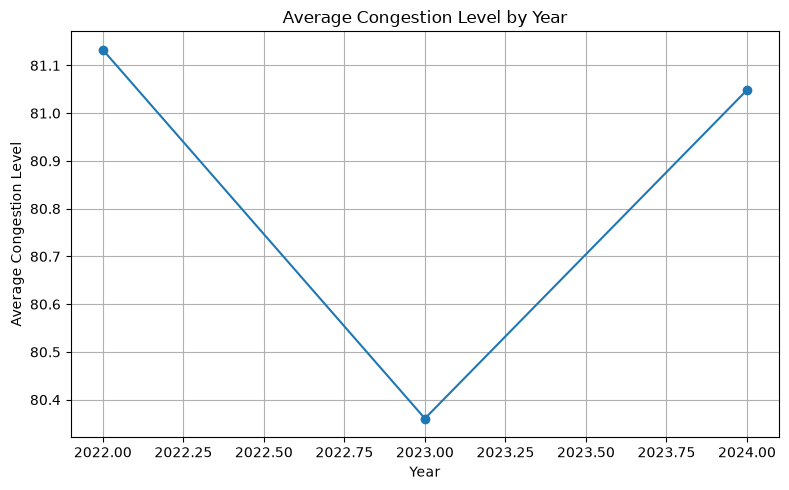

In [68]:
plt.figure(figsize=(8, 5))

plt.plot(
    year_congestion.index,
    year_congestion.values,
    marker='o'
)

plt.title('Average Congestion Level by Year')
plt.xlabel('Year')
plt.ylabel('Average Congestion Level')
plt.grid(True)

plt.tight_layout()

plt.savefig(
    '../outputs/charts/congestion_trend_by_year.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### 10.2 Congestion by Area

This visualization compares average congestion levels across different areas in Bangalore to identify locations experiencing higher traffic pressure.

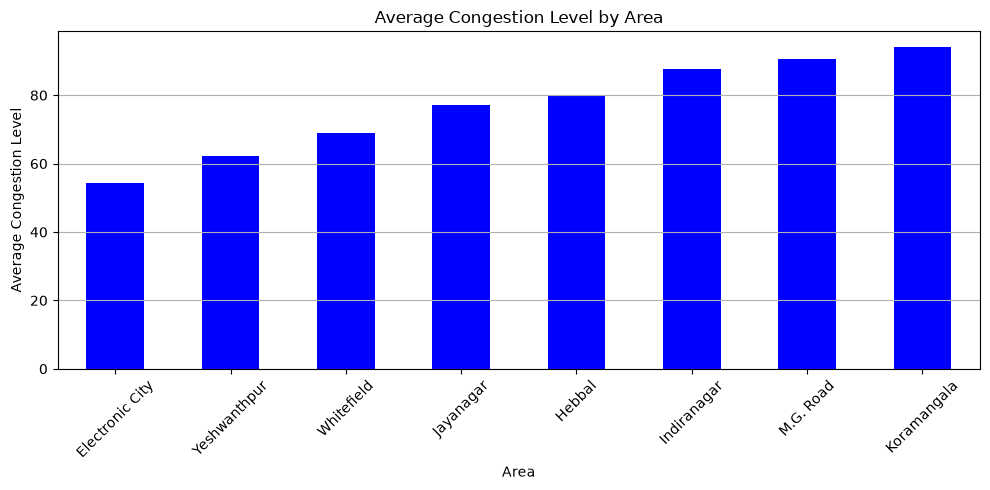

In [69]:
plt.figure(figsize=(10, 5))

area_congestion.sort_values().plot(kind='bar',color = 'blue')

plt.title('Average Congestion Level by Area')
plt.xlabel('Area')
plt.ylabel('Average Congestion Level')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()

plt.savefig(
    '../outputs/charts/congestion_by_area.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### 10.3 Traffic Volume by Area

This visualization compares average traffic volume across different areas to identify locations with higher traffic demand.

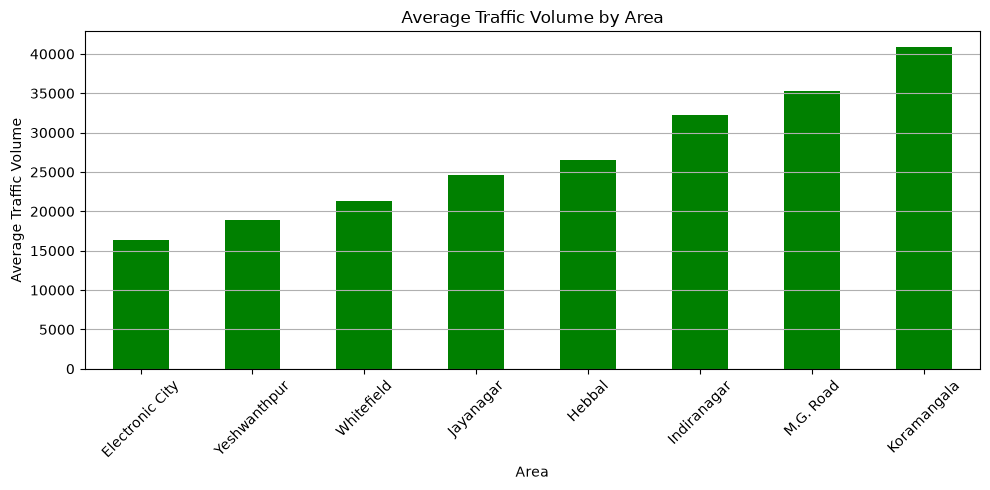

In [70]:
plt.figure(figsize=(10, 5))

area_traffic.sort_values().plot(kind='bar',color='green')

plt.title('Average Traffic Volume by Area')
plt.xlabel('Area')
plt.ylabel('Average Traffic Volume')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()

plt.savefig(
    '../outputs/charts/traffic_volume_by_area.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### 10.4 Average Speed by Area

This visualization compares average vehicle speed across different areas to identify locations with lower traffic movement efficiency.

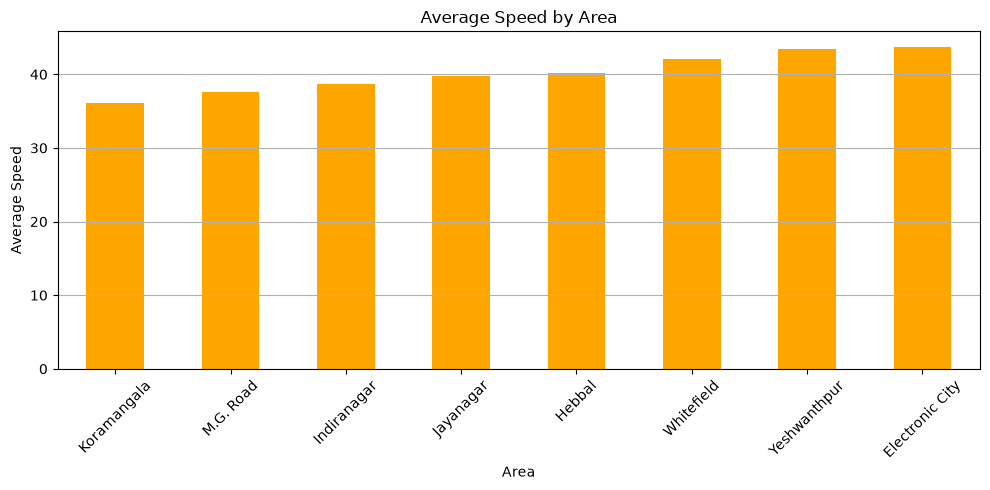

In [71]:
plt.figure(figsize=(10, 5))

area_speed.sort_values().plot(kind='bar',color='orange')

plt.title('Average Speed by Area')
plt.xlabel('Area')
plt.ylabel('Average Speed')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()

plt.savefig(
    '../outputs/charts/Average_Speed_by_Area',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### 10.5 Road Capacity Utilization by Area

This visualization compares average road capacity utilization across different areas to identify locations experiencing higher infrastructure pressure.

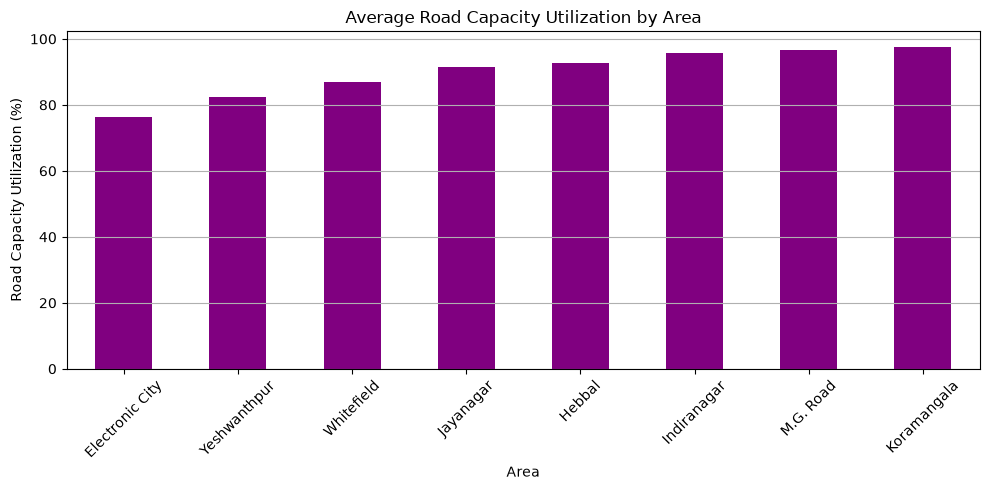

In [72]:
plt.figure(figsize=(10, 5))

area_capacity.sort_values().plot(
    kind='bar',
    color='purple'
)

plt.title('Average Road Capacity Utilization by Area')
plt.xlabel('Area')
plt.ylabel('Road Capacity Utilization (%)')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()

plt.savefig(
    '../outputs/charts/Road_Capacity_Utilization_by_Area',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### 10.6 Travel Time Index by Area

This visualization compares the average Travel Time Index across different areas to identify locations experiencing greater travel delay.

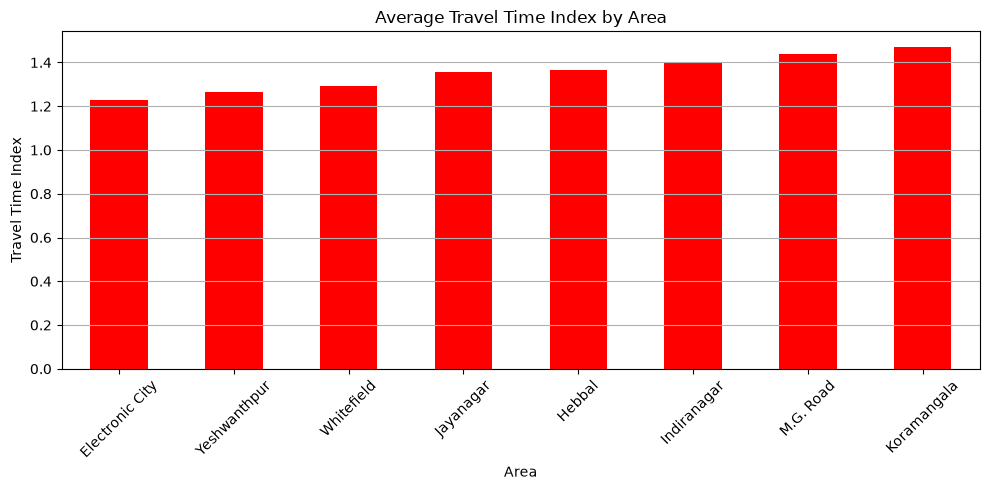

In [73]:
plt.figure(figsize=(10, 5))

area_tti.sort_values().plot(
    kind='bar',
    color='red'
)

plt.title('Average Travel Time Index by Area')
plt.xlabel('Area')
plt.ylabel('Travel Time Index')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()

plt.savefig(
    '../outputs/charts/Travel_Time_Index_by_Area',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### 10.7 Congestion Trend by Month

This visualization shows the average congestion level across months to identify seasonal variations in traffic conditions.

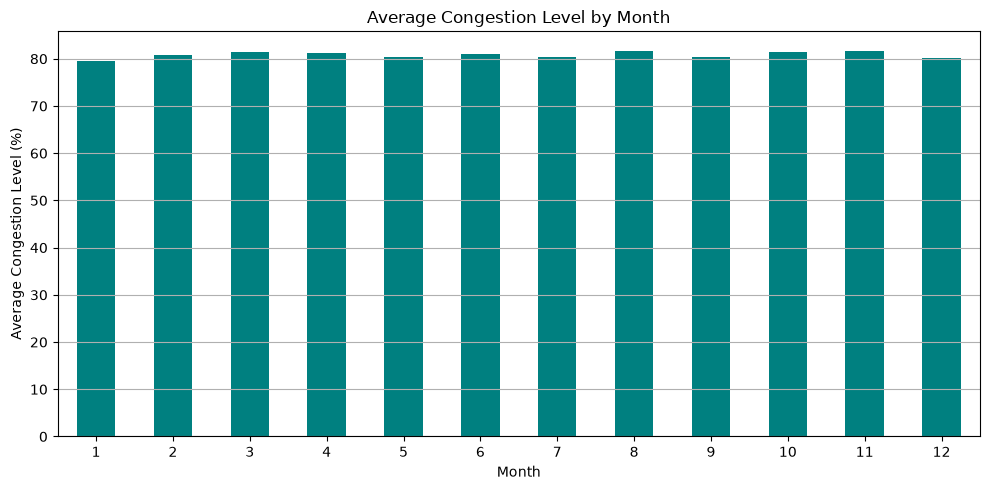

In [74]:

plt.figure(figsize=(10, 5))

month_congestion.sort_index().plot(
    kind='bar',
    color='teal'
)

plt.title('Average Congestion Level by Month')
plt.xlabel('Month')
plt.ylabel('Average Congestion Level (%)')
plt.xticks(rotation=0)
plt.grid(axis='y')

plt.tight_layout()

plt.savefig(
    '../outputs/charts/Congestion_Trend_by_Month',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### 10.8 Traffic Volume Trend by Month

This visualization shows the average traffic volume across months to identify seasonal variations in traffic demand.

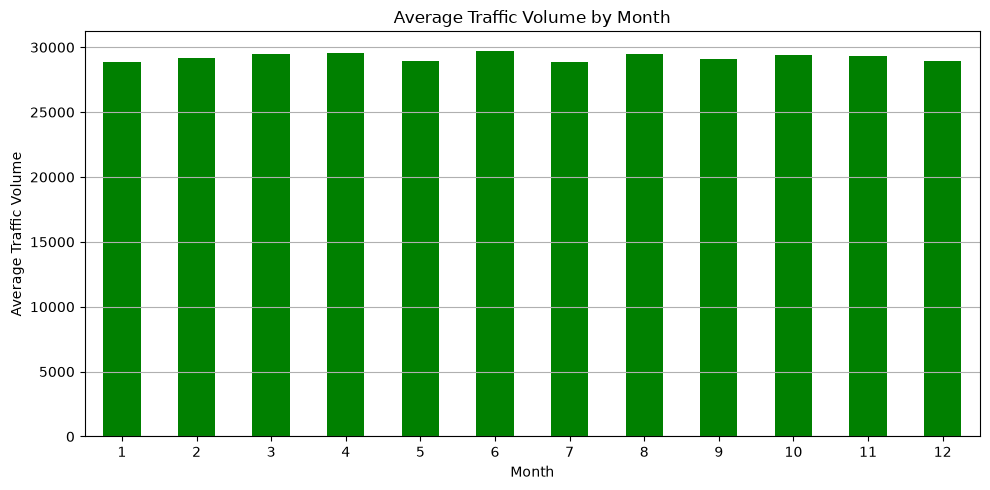

In [75]:
plt.figure(figsize=(10, 5))

month_traffic.sort_index().plot(
    kind='bar',
    color='green'
)

plt.title('Average Traffic Volume by Month')
plt.xlabel('Month')
plt.ylabel('Average Traffic Volume')
plt.xticks(rotation=0)
plt.grid(axis='y')

plt.tight_layout()

plt.savefig(
    '../outputs/charts/Traffic_Volume_Trend_by_Month',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### 10.9 Congestion Level by Day of Week

This visualization compares average congestion levels across days of the week to identify weekday and weekend traffic patterns.

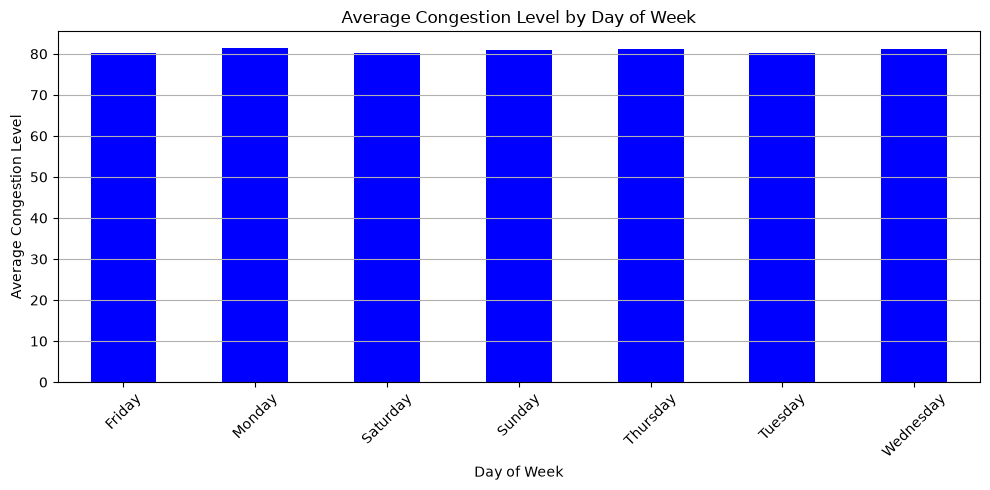

In [76]:
plt.figure(figsize=(10, 5))

day_congestion.plot(
    kind='bar',
    color='blue'
)

plt.title('Average Congestion Level by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Average Congestion Level')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()

plt.savefig(
    '../outputs/charts/Congestion_Level_by_Day_of_Week',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### 10.10 Traffic Volume by Day of Week

This visualization compares average traffic volume across days of the week to identify differences in traffic demand between weekdays and weekends.

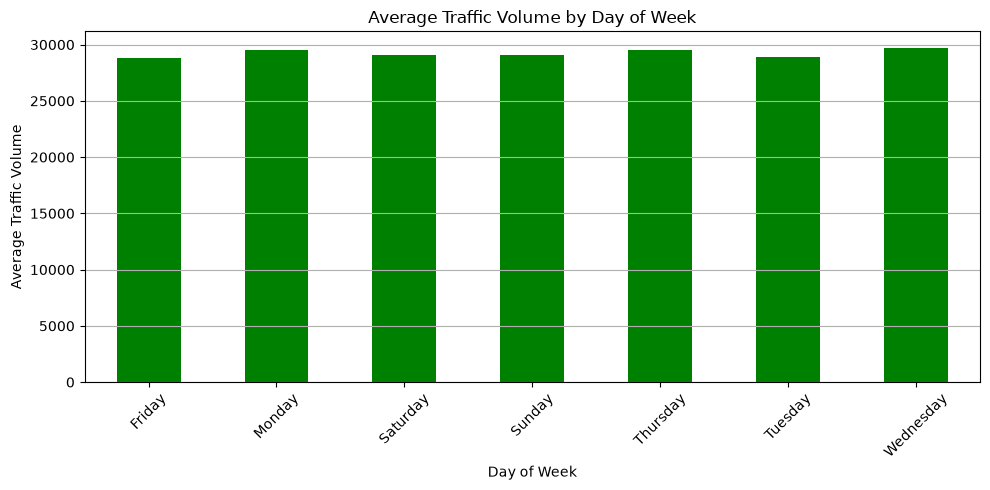

In [77]:
plt.figure(figsize=(10, 5))

day_traffic.plot(
    kind='bar',
    color='green'
)

plt.title('Average Traffic Volume by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Average Traffic Volume')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()

plt.savefig(
    '../outputs/charts/Traffic_Volume_by_Day_of_Week',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### 10.11 Traffic Volume vs Congestion

This visualization examines the relationship between traffic volume and congestion level to understand whether higher traffic demand is associated with increased congestion.

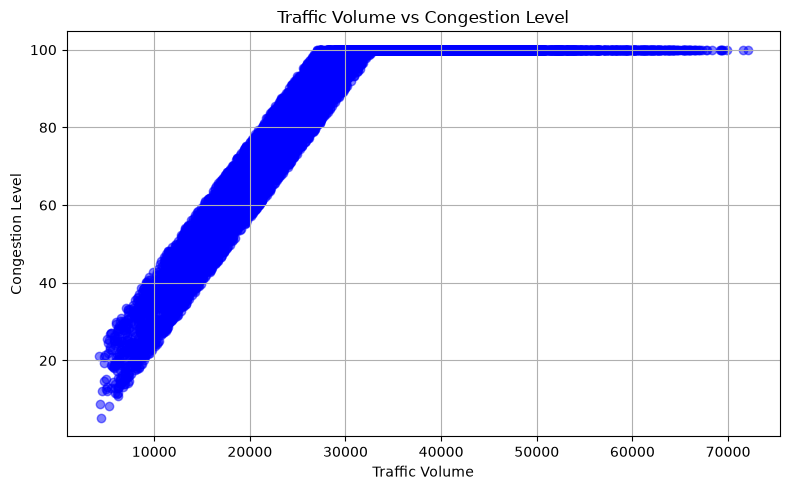

In [78]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['traffic_volume'],
    df['congestion_level'],
    alpha=0.5,
    color='blue'
)

plt.title('Traffic Volume vs Congestion Level')
plt.xlabel('Traffic Volume')
plt.ylabel('Congestion Level')
plt.grid(True)

plt.tight_layout()

plt.savefig(
    '../outputs/charts/Traffic_Volume_vs_Congestion',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### 10.12 Average Speed vs Congestion

This visualization examines the relationship between average vehicle speed and congestion level to understand whether lower speeds are associated with higher congestion.

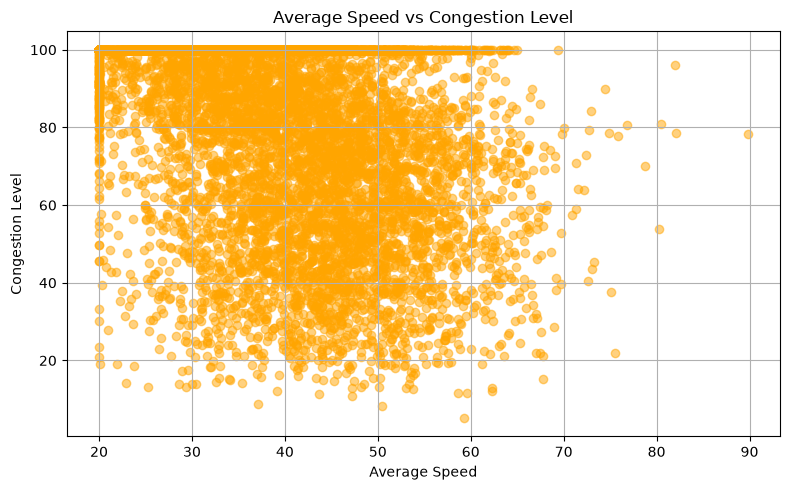

In [79]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['average_speed'],
    df['congestion_level'],
    alpha=0.5,
    color='orange'
)

plt.title('Average Speed vs Congestion Level')
plt.xlabel('Average Speed')
plt.ylabel('Congestion Level')
plt.grid(True)

plt.tight_layout()

plt.savefig(
    '../outputs/charts/Average_Speed_vs_Congestion',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### 10.13 Road Capacity Utilization vs Congestion

This visualization examines the relationship between road capacity utilization and congestion level to understand whether higher infrastructure utilization is associated with greater congestion.

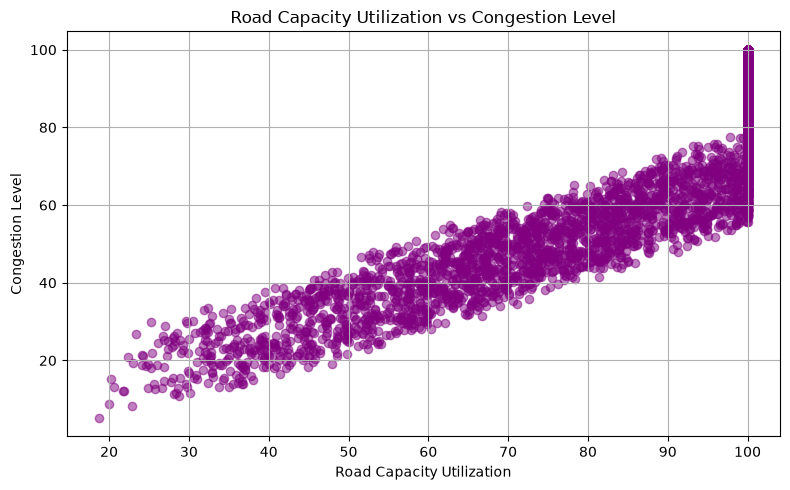

In [80]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['road_capacity_utilization'],
    df['congestion_level'],
    alpha=0.5,
    color='purple'
)

plt.title('Road Capacity Utilization vs Congestion Level')
plt.xlabel('Road Capacity Utilization')
plt.ylabel('Congestion Level')
plt.grid(True)

plt.tight_layout()

plt.savefig(
    '../outputs/charts/Road_Capacity_Utilization_vs_Congestion',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### 10.14 Travel Time Index vs Congestion

This visualization examines the relationship between Travel Time Index and congestion level to understand how increasing travel delays are associated with congestion.

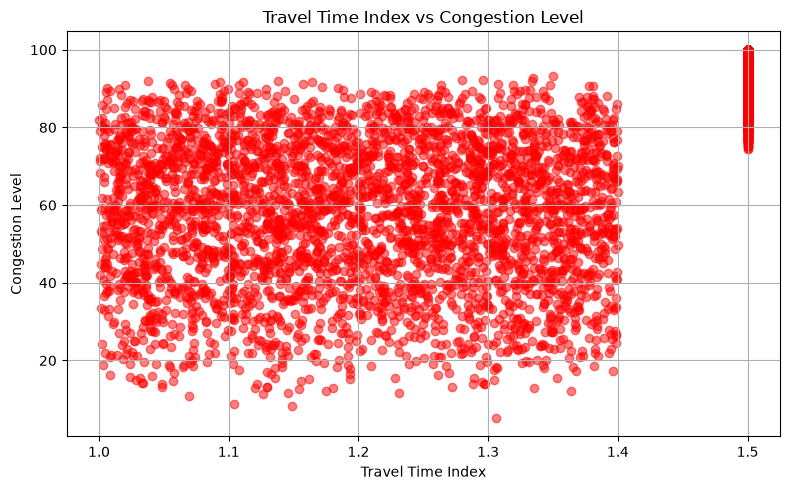

In [81]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['travel_time_index'],
    df['congestion_level'],
    alpha=0.5,
    color='red'
)

plt.title('Travel Time Index vs Congestion Level')
plt.xlabel('Travel Time Index')
plt.ylabel('Congestion Level')
plt.grid(True)

plt.tight_layout()

plt.savefig(
    '../outputs/charts/Travel_Time_Index_vs_Congestion',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### 10.15 Congestion Level by Weather Conditions

This visualization compares average congestion levels under different weather conditions to identify whether weather conditions are associated with changes in traffic congestion.

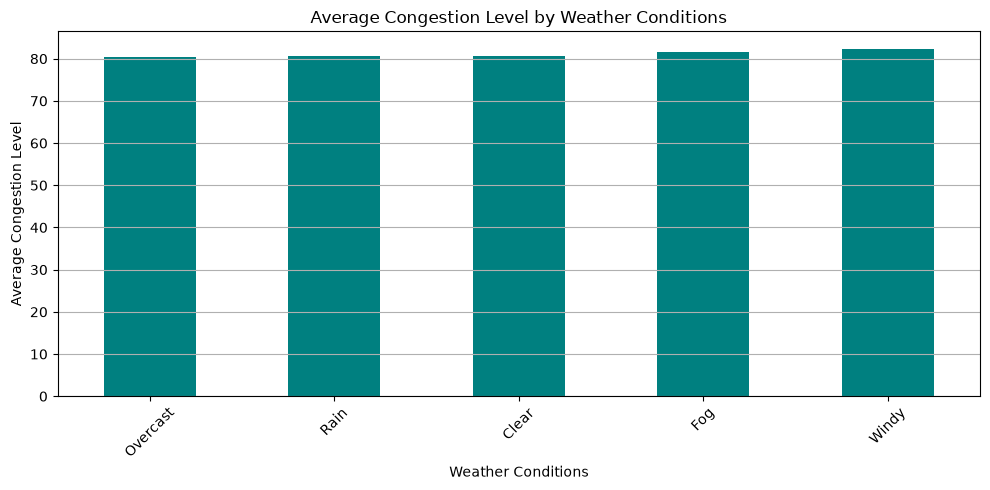

In [82]:
plt.figure(figsize=(10, 5))

weather_congestion.sort_values().plot(
    kind='bar',
    color='teal'
)

plt.title('Average Congestion Level by Weather Conditions')
plt.xlabel('Weather Conditions')
plt.ylabel('Average Congestion Level')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()

plt.savefig(
    '../outputs/charts/Congestion_Level_by_Weather_Conditions',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### 10.16 Congestion Level by Roadwork Activity

This visualization compares average congestion levels between observations with and without roadwork or construction activity.

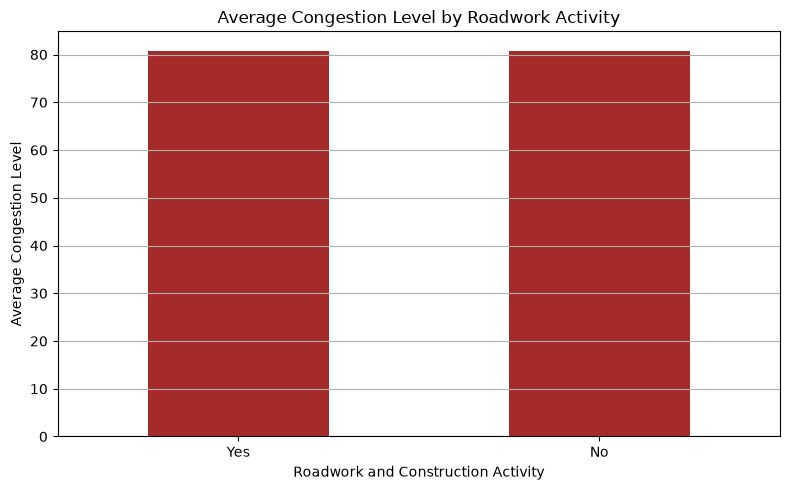

In [83]:
plt.figure(figsize=(8, 5))

roadwork_congestion.sort_values().plot(
    kind='bar',
    color='brown'
)

plt.title('Average Congestion Level by Roadwork Activity')
plt.xlabel('Roadwork and Construction Activity')
plt.ylabel('Average Congestion Level')
plt.xticks(rotation=0)
plt.grid(axis='y')

plt.tight_layout()

plt.savefig(
    '../outputs/charts/Congestion_Level_by_Roadwork_Activity',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### 10.17 Pedestrian and Cyclist Activity by Area

This visualization compares the average pedestrian and cyclist count across different areas. It helps identify areas with higher non-motorized mobility activity.

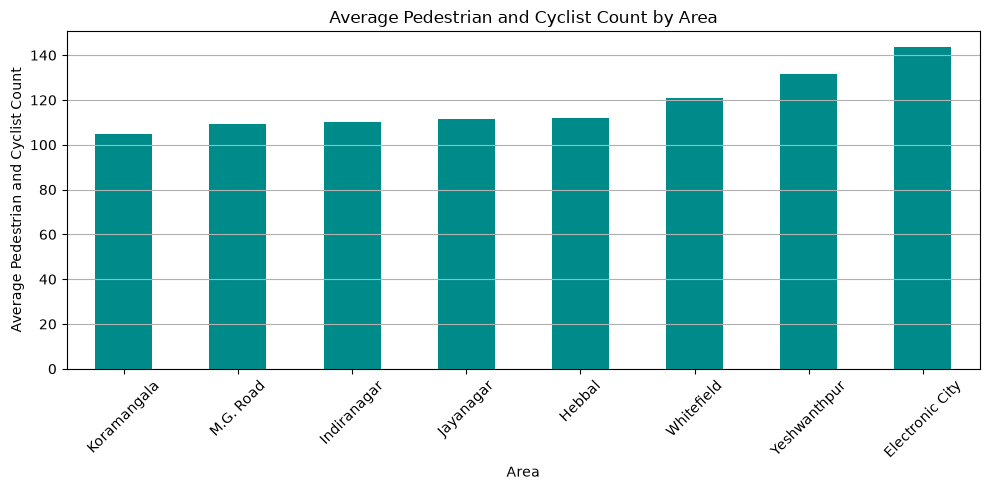

In [84]:
plt.figure(figsize=(10, 5))

pedestrian_area = df.groupby('area_name')['pedestrian_and_cyclist_count'].mean().sort_values()

pedestrian_area.plot(
    kind='bar',
    color='darkcyan'
)

plt.title('Average Pedestrian and Cyclist Count by Area')
plt.xlabel('Area')
plt.ylabel('Average Pedestrian and Cyclist Count')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()

plt.savefig(
    '../outputs/charts/Pedestrian_and_Cyclist_Activity_by_Area',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### 10.18 Average Traffic Signal Compliance by Area

This visualization compares the average traffic signal compliance across different areas. It helps identify areas with stronger or weaker compliance with traffic signals.

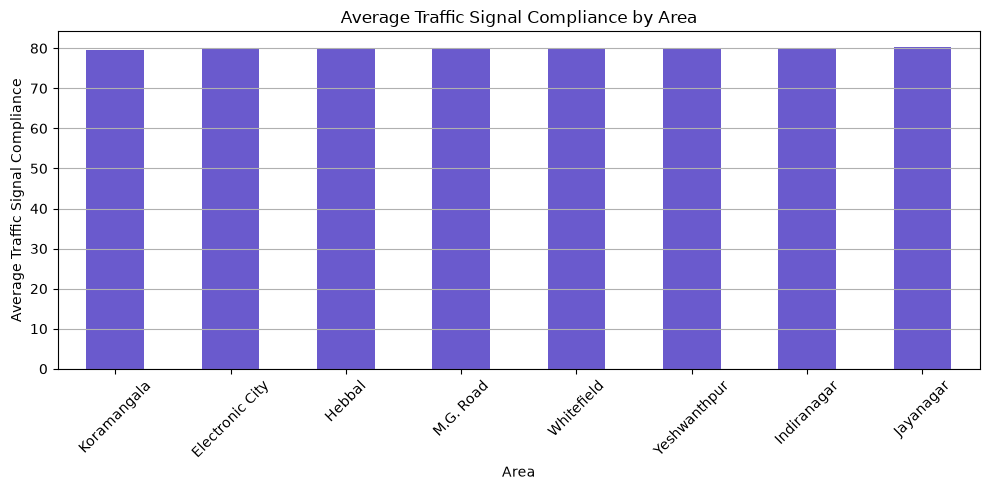

In [85]:
plt.figure(figsize=(10, 5))

signal_area = df.groupby('area_name')['traffic_signal_compliance'].mean().sort_values()

signal_area.plot(
    kind='bar',
    color='slateblue'
)

plt.title('Average Traffic Signal Compliance by Area')
plt.xlabel('Area')
plt.ylabel('Average Traffic Signal Compliance')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()

plt.savefig(
    '../outputs/charts/Average_Traffic_Signal_Compliance_by_Area',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### 10.19 Average Public Transport Usage by Area

This visualization compares average public transport usage across different areas. It helps identify areas with higher or lower public transport utilization.

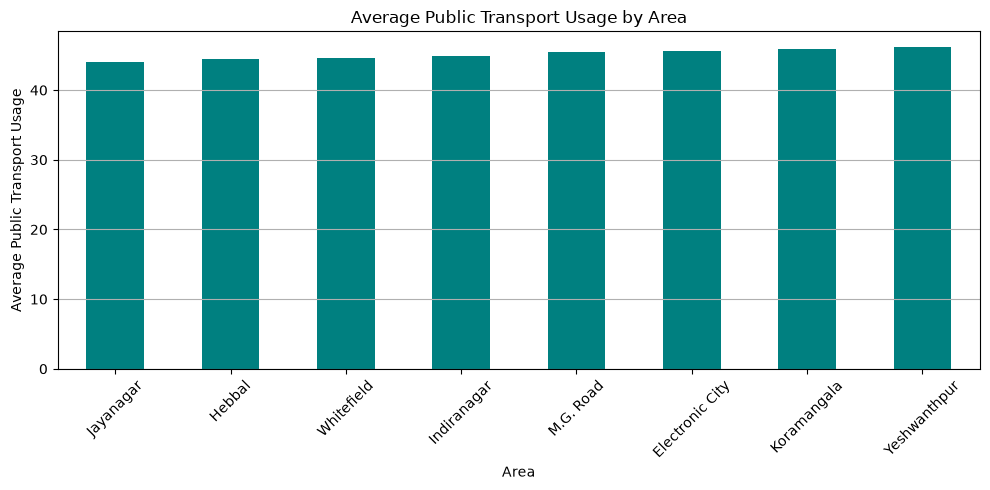

In [86]:
plt.figure(figsize=(10, 5))

public_transport_area = df.groupby('area_name')['public_transport_usage'].mean().sort_values()

public_transport_area.plot(
    kind='bar',
    color='teal'
)

plt.title('Average Public Transport Usage by Area')
plt.xlabel('Area')
plt.ylabel('Average Public Transport Usage')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()

plt.savefig(
    '../outputs/charts/Average_Public_Transport_Usage_by_Area',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### 10.20 Average Parking Usage by Area

This visualization compares the average parking usage across different areas. It helps identify areas with higher parking demand and potential parking-related pressure.

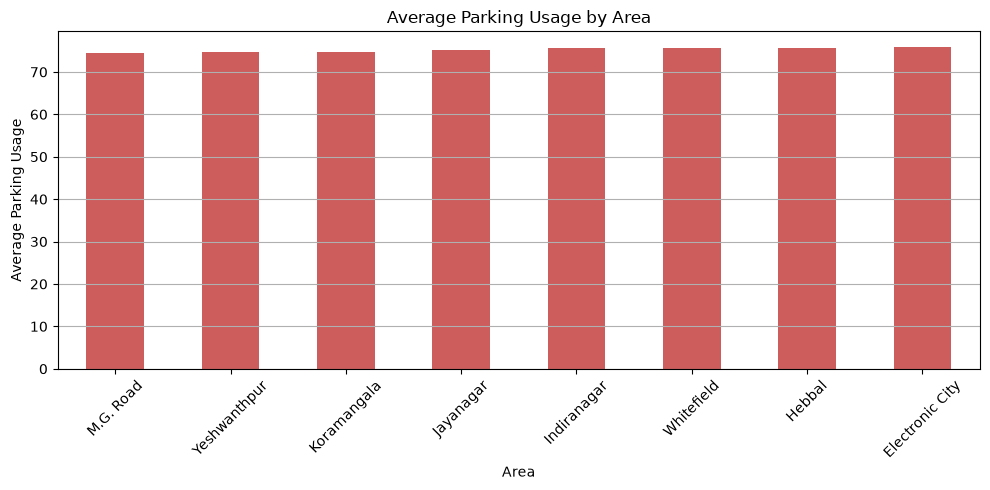

In [87]:
plt.figure(figsize=(10, 5))

parking_area = df.groupby('area_name')['parking_usage'].mean().sort_values()

parking_area.plot(
    kind='bar',
    color='indianred'
)

plt.title('Average Parking Usage by Area')
plt.xlabel('Area')
plt.ylabel('Average Parking Usage')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()

plt.savefig(
    '../outputs/charts/Average_Parking_Usage_by_Area',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# 11. Dashboard

This section develops an interactive mobility dashboard to help transport planners explore traffic conditions across different areas, dates, congestion levels, and road intersections.

The dashboard focuses on traffic flow, congestion, delay, capacity utilization, and mobility performance using the available dataset fields.

In [88]:
import ipywidgets as widgets
from IPython.display import display

In [ ]:
# ============================================================
# 🚦 URBAN TRAFFIC MOBILITY DASHBOARD
# FINAL PROFESSIONAL DASHBOARD
# ============================================================

import pandas as pd
import numpy as np
import plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import display


# ============================================================
# 1. PREPARE DATA
# ============================================================

df['date'] = pd.to_datetime(df['date'])

df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['day_name'] = df['date'].dt.day_name()


# ============================================================
# GET AREA NAMES
# ============================================================

areas = sorted(
    df['area_name']
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)


# ============================================================
# GET YEARS
# ============================================================

years = sorted(
    df['year']
    .dropna()
    .astype(int)
    .unique()
    .tolist()
)


# ============================================================
# 2. FILTER CONTROLS
# ============================================================

area_filter = widgets.Dropdown(

    options=[
        ('All Areas', 'All Areas')
    ] + [
        (area, area)
        for area in areas
    ],

    value='All Areas',

    description='',

    layout=widgets.Layout(
        width='240px',
        height='38px',
        margin='0',
        padding='0'
    )

)


year_filter = widgets.Dropdown(

    options=[
        ('All Years', 'All Years')
    ] + [
        (str(year), year)
        for year in years
    ],

    value='All Years',

    description='',

    layout=widgets.Layout(
        width='240px',
        height='38px',
        margin='0',
        padding='0'
    )

)


# ============================================================
# 3. FILTER LABELS
# ============================================================

area_label = widgets.HTML(

    value="""
    <div style="
        font-family:Arial,sans-serif;
        font-size:12px;
        font-weight:600;
        color:#334155;
        margin:0 0 6px 0;
        padding:0;
        line-height:16px;
    ">
        📍 Area
    </div>
    """,

    layout=widgets.Layout(
        width='240px',
        height='18px',
        margin='0',
        padding='0'
    )

)


year_label = widgets.HTML(

    value="""
    <div style="
        font-family:Arial,sans-serif;
        font-size:12px;
        font-weight:600;
        color:#334155;
        margin:0 0 6px 0;
        padding:0;
        line-height:16px;
    ">
        📅 Year
    </div>
    """,

    layout=widgets.Layout(
        width='240px',
        height='18px',
        margin='0',
        padding='0'
    )

)


# ============================================================
# 4. AREA FILTER BOX
# ============================================================

area_box = widgets.VBox(

    [
        area_label,
        area_filter
    ],

    layout=widgets.Layout(
        width='240px',
        min_width='240px',
        max_width='240px',
        height='62px',
        margin='0',
        padding='0',
        align_items='flex-start',
        overflow='visible'
    )

)


# ============================================================
# 5. YEAR FILTER BOX
# ============================================================

year_box = widgets.VBox(

    [
        year_label,
        year_filter
    ],

    layout=widgets.Layout(
        width='240px',
        min_width='240px',
        max_width='240px',
        height='62px',
        margin='0',
        padding='0',
        align_items='flex-start',
        overflow='visible'
    )

)


# ============================================================
# 6. FILTER TITLE
# ============================================================

filter_title = widgets.HTML(

    value="""
    <div style="
        font-family:Arial,sans-serif;
        font-size:12px;
        font-weight:700;
        color:#1e293b;
        margin:0 0 9px 0;
        padding:0;
        line-height:16px;
    ">
        Select Filters
    </div>
    """,

    layout=widgets.Layout(
        width='100%',
        height='16px',
        margin='0 0 9px 0',
        padding='0'
    )

)


# ============================================================
# 7. FILTER ROW
# ============================================================

filter_row = widgets.HBox(

    [
        area_box,
        year_box
    ],

    layout=widgets.Layout(

        width='100%',

        height='62px',

        margin='0',

        padding='0',

        gap='0px',

        align_items='flex-start',

        justify_content='flex-start',

        overflow='visible'

    )

)


# ============================================================
# 8. COMPLETE FILTER SECTION
# ============================================================

filter_section = widgets.VBox(

    [
        filter_title,
        filter_row
    ],

    layout=widgets.Layout(

        width='100%',

        height='89px',

        margin='0 0 18px 0',

        padding='10px 16px',

        align_items='flex-start',

        overflow='visible'

    )

)


# ============================================================
# 9. MAIN DASHBOARD OUTPUT
# ============================================================

dashboard_output = widgets.Output()


# ============================================================
# 10. KPI CARD FUNCTION
# ============================================================

def create_kpi_card(
    title,
    value,
    unit,
    icon,
    card_bg,
    border_color,
    icon_bg,
    value_color,
    spark_values
):

    values = np.array(
        spark_values,
        dtype=float
    )


    # --------------------------------------------------------
    # CREATE SPARKLINE
    # --------------------------------------------------------

    if len(values) > 1:

        min_val = values.min()
        max_val = values.max()

        if max_val == min_val:

            normalized = np.full(
                len(values),
                0.5
            )

        else:

            normalized = (
                (values - min_val)
                /
                (max_val - min_val)
            )

        points = []

        for i, v in enumerate(normalized):

            x = (
                5
                +
                (
                    i
                    *
                    90
                    /
                    (len(normalized) - 1)
                )
            )

            y = (
                31
                -
                (v * 24)
            )

            points.append(
                f"{x:.1f},{y:.1f}"
            )

        points_string = " ".join(points)

    else:

        points_string = "5,20 95,20"


    sparkline = f"""
    <svg
        width="95"
        height="40"
        viewBox="0 0 100 40"
    >

        <polygon
            points="
                {points_string}
                95,40
                5,40
            "
            fill="{value_color}"
            opacity="0.08"
        />

        <polyline
            points="{points_string}"
            fill="none"
            stroke="{value_color}"
            stroke-width="1.8"
            stroke-linecap="round"
            stroke-linejoin="round"
            opacity="0.60"
        />

    </svg>
    """


    # --------------------------------------------------------
    # KPI CARD
    # --------------------------------------------------------

    return widgets.HTML(

        value=f"""

        <div style="
            width:100%;
            height:108px;

            background:{card_bg};

            border:1px solid {border_color};

            border-radius:9px;

            padding:14px;

            box-sizing:border-box;

            position:relative;

            overflow:hidden;

            box-shadow:
                0 2px 6px
                rgba(15,23,42,0.06);
        ">


            <!-- ICON -->

            <div style="
                position:absolute;

                left:12px;
                top:16px;

                width:48px;
                height:48px;

                background:{icon_bg};

                border-radius:9px;

                display:flex;
                align-items:center;
                justify-content:center;

                font-size:22px;
            ">

                {icon}

            </div>


            <!-- TEXT -->

            <div style="
                position:absolute;

                left:72px;
                top:15px;
            ">


                <!-- TITLE -->

                <div style="
                    font-family:Arial,sans-serif;

                    font-size:11px;

                    font-weight:500;

                    color:#334155;

                    margin-bottom:6px;

                    white-space:nowrap;
                ">

                    {title}

                </div>


                <!-- VALUE -->

                <div style="
                    font-family:Arial,sans-serif;

                    font-size:25px;

                    line-height:25px;

                    font-weight:700;

                    color:{value_color};
                ">

                    {value}

                </div>


                <!-- UNIT -->

                <div style="
                    font-family:Arial,sans-serif;

                    font-size:10px;

                    color:#64748b;

                    margin-top:3px;

                    white-space:nowrap;
                ">

                    {unit}

                </div>

            </div>


            <!-- SPARKLINE -->

            <div style="
                position:absolute;

                right:8px;
                bottom:8px;

                width:95px;
                height:40px;
            ">

                {sparkline}

            </div>

        </div>

        """

    )


# ============================================================
# 11. CHART CARD FUNCTION
# ============================================================

def create_chart_card(
    title,
    icon,
    icon_color,
    figure
):

    chart_output = widgets.Output(

        layout=widgets.Layout(
            width='100%',
            height='300px',
            overflow='hidden'
        )

    )


    title_html = widgets.HTML(

        value=f"""

        <div style="
            width:100%;
            height:42px;

            padding:12px 15px 0 15px;

            box-sizing:border-box;

            font-family:Arial,sans-serif;

            font-size:15px;

            font-weight:600;

            color:#1e293b;
        ">

            <span style="
                color:{icon_color};
                font-size:16px;
            ">

                {icon}

            </span>

            &nbsp;

            {title}

        </div>

        """

    )


    with chart_output:

        display(figure)


    return widgets.VBox(

        [
            title_html,
            chart_output
        ],

        layout=widgets.Layout(

            width='49%',

            height='350px',

            flex='0 0 49%',

            background='#ffffff',

            border='1px solid #e2e8f0',

            border_radius='10px',

            padding='0',

            margin='0',

            overflow='hidden'

        )

    )


# ============================================================
# 12. BUILD DASHBOARD
# ============================================================

def build_dashboard(
    area='All Areas',
    year='All Years'
):


    # ========================================================
    # FILTER DATA
    # ========================================================

    data = df.copy()


    if area != 'All Areas':

        data = data[
            data['area_name'].astype(str) == str(area)
        ]


    if year != 'All Years':

        data = data[
            data['year'] == int(year)
        ]


    # ========================================================
    # EMPTY DATA CHECK
    # ========================================================

    if data.empty:

        dashboard_output.clear_output(
            wait=True
        )

        with dashboard_output:

            display(

                widgets.HTML(

                    value="""
                    <div style="
                        width:100%;
                        padding:30px;
                        box-sizing:border-box;
                        text-align:center;
                        font-family:Arial,sans-serif;
                        color:#dc2626;
                        font-size:14px;
                        font-weight:600;
                    ">

                        No data available for the selected filters.

                    </div>
                    """

                )

            )

        return


    # ========================================================
    # KPI VALUES
    # ========================================================

    avg_volume = (
        data['traffic_volume'].mean()
    )


    avg_congestion = (
        data['congestion_level'].mean()
    )


    avg_speed = (
        data['average_speed'].mean()
    )


    avg_capacity = (
        data['road_capacity_utilization'].mean()
    )


    # ========================================================
    # RELIABILITY
    # ========================================================

    congestion_threshold = (

        df['congestion_level']
        .quantile(0.75)

    )


    high_congestion_pct = (

        data['congestion_level']
        .ge(congestion_threshold)
        .mean()
        * 100

    )


    reliability = (
        100 - high_congestion_pct
    )


    # ========================================================
    # HEADER
    # ========================================================

    header = widgets.HTML(

        value=f"""

        <div style="
            width:100%;
            height:92px;

            background:#173f68;

            border-radius:9px;

            padding:16px 22px;

            box-sizing:border-box;

            color:white;

            margin:0 0 10px 0;
        ">


            <div style="
                display:flex;

                justify-content:space-between;

                align-items:center;

                height:100%;
            ">


                <!-- LEFT -->

                <div>


                    <div style="
                        font-family:Arial,sans-serif;

                        font-size:25px;

                        font-weight:700;

                        line-height:1.15;

                        margin-bottom:7px;
                    ">

                        🚦 Urban Traffic Mobility Dashboard

                    </div>


                    <div style="
                        font-family:Arial,sans-serif;

                        font-size:12px;

                        color:#dbeafe;
                    ">

                        Traffic flow, congestion, capacity and reliability analysis

                        &nbsp; • &nbsp;

                        {area}

                        &nbsp; • &nbsp;

                        {year}

                    </div>

                </div>


                <!-- RIGHT -->

                <div style="
                    text-align:right;

                    color:#e2e8f0;

                    font-family:Arial,sans-serif;

                    font-size:11px;

                    line-height:1.5;
                ">

                    <div>

                        📅 Analysis Period

                    </div>


                    <div style="
                        font-size:13px;

                        font-weight:600;

                        color:white;
                    ">

                        {year}

                    </div>

                </div>

            </div>

        </div>

        """

    )


    # ========================================================
    # KPI SPARKLINES
    # ========================================================

    volume_spark = (

        data.groupby('date')
        ['traffic_volume']
        .mean()
        .tail(30)
        .values

    )


    congestion_spark = (

        data.groupby('date')
        ['congestion_level']
        .mean()
        .tail(30)
        .values

    )


    speed_spark = (

        data.groupby('date')
        ['average_speed']
        .mean()
        .tail(30)
        .values

    )


    capacity_spark = (

        data.groupby('date')
        ['road_capacity_utilization']
        .mean()
        .tail(30)
        .values

    )


    # ========================================================
    # KPI CARDS
    # ========================================================

    kpi_volume = create_kpi_card(

        title='Average Traffic Volume',

        value=f'{avg_volume:,.0f}',

        unit='vehicles',

        icon='🚗',

        card_bg='#eef6ff',

        border_color='#bfdbfe',

        icon_bg='#dbeafe',

        value_color='#2563eb',

        spark_values=volume_spark

    )


    kpi_congestion = create_kpi_card(

        title='Average Congestion',

        value=f'{avg_congestion:.1f}%',

        unit='congestion level',

        icon='🚘',

        card_bg='#fff7ed',

        border_color='#fed7aa',

        icon_bg='#ffedd5',

        value_color='#ea580c',

        spark_values=congestion_spark

    )


    kpi_speed = create_kpi_card(

        title='Average Speed',

        value=f'{avg_speed:.1f}',

        unit='km/h',

        icon='⏱',

        card_bg='#effaf4',

        border_color='#bbf7d0',

        icon_bg='#dcfce7',

        value_color='#15803d',

        spark_values=speed_spark

    )


    kpi_capacity = create_kpi_card(

        title='Capacity Utilization',

        value=f'{avg_capacity:.1f}%',

        unit='of road capacity',

        icon='🛣',

        card_bg='#f7f3ff',

        border_color='#ddd6fe',

        icon_bg='#ede9fe',

        value_color='#6d28d9',

        spark_values=capacity_spark

    )


    # ========================================================
    # KPI ALIGNMENT
    # ========================================================

    for card in [

        kpi_volume,
        kpi_congestion,
        kpi_speed,
        kpi_capacity

    ]:

        card.layout = widgets.Layout(

            width='24%',

            height='108px',

            flex='0 0 24%',

            margin='0'

        )


    kpi_row = widgets.HBox(

        [

            kpi_volume,
            kpi_congestion,
            kpi_speed,
            kpi_capacity

        ],

        layout=widgets.Layout(

            width='100%',

            height='108px',

            display='flex',

            flex_flow='row nowrap',

            justify_content='space-between',

            align_items='stretch',

            margin='0 0 18px 0'

        )

    )


    # ========================================================
    # CHART 1 — TRAFFIC VOLUME
    # ========================================================

    volume_data = (

        data.groupby(
            'date',
            as_index=False
        )
        ['traffic_volume']
        .mean()
        .sort_values('date')

    )


    fig_volume = go.Figure()


    fig_volume.add_trace(

        go.Scatter(

            x=volume_data['date'],

            y=volume_data[
                'traffic_volume'
            ],

            mode='lines',

            fill='tozeroy',

            line=dict(

                color='#4169e1',

                width=2

            ),

            fillcolor='rgba(65,105,225,0.18)',

            hovertemplate=

            '<b>Date:</b> %{x|%d %b %Y}<br>'

            '<b>Traffic Volume:</b> %{y:,.0f}'

            '<extra></extra>'

        )

    )


    fig_volume.update_layout(

        height=300,

        autosize=True,

        template='plotly_white',

        margin=dict(

            l=55,
            r=18,
            t=5,
            b=45

        ),

        xaxis=dict(

            title='Date',

            showgrid=True,

            gridcolor='#edf2f7',

            zeroline=False

        ),

        yaxis=dict(

            title='Traffic Volume',

            showgrid=True,

            gridcolor='#edf2f7',

            zeroline=False

        ),

        hovermode='x unified',

        showlegend=False,

        paper_bgcolor='white',

        plot_bgcolor='white'

    )


    volume_card = create_chart_card(

        'Traffic Volume Trend',

        '📊',

        '#2563eb',

        fig_volume

    )


    # ========================================================
    # CHART 2 — CONGESTION
    # ========================================================

    congestion_data = (

        data.groupby(
            'date',
            as_index=False
        )
        ['congestion_level']
        .mean()
        .sort_values('date')

    )


    fig_congestion = go.Figure()


    fig_congestion.add_trace(

        go.Scatter(

            x=congestion_data['date'],

            y=congestion_data[
                'congestion_level'
            ],

            mode='lines',

            line=dict(

                color='#dc2626',

                width=2

            ),

            hovertemplate=

            '<b>Date:</b> %{x|%d %b %Y}<br>'

            '<b>Congestion:</b> %{y:.1f}%'

            '<extra></extra>'

        )

    )


    fig_congestion.update_layout(

        height=300,

        autosize=True,

        template='plotly_white',

        margin=dict(

            l=55,
            r=18,
            t=5,
            b=45

        ),

        xaxis=dict(

            title='Date',

            showgrid=True,

            gridcolor='#edf2f7',

            zeroline=False

        ),

        yaxis=dict(

            title='Congestion (%)',

            range=[0,100],

            showgrid=True,

            gridcolor='#edf2f7',

            zeroline=False

        ),

        hovermode='x unified',

        showlegend=False,

        paper_bgcolor='white',

        plot_bgcolor='white'

    )


    congestion_card = create_chart_card(

        'Congestion Trend',

        '🚗',

        '#dc2626',

        fig_congestion

    )


    # ========================================================
    # CHART ROW 1
    # ========================================================

    chart_row_1 = widgets.HBox(

        [

            volume_card,
            congestion_card

        ],

        layout=widgets.Layout(

            width='100%',

            height='350px',

            display='flex',

            flex_flow='row nowrap',

            justify_content='space-between',

            gap='14px',

            margin='0 0 14px 0'

        )

    )


    # ========================================================
    # CHART 3 — SPEED
    # ========================================================

    speed_data = (

        data.groupby(
            'date',
            as_index=False
        )
        ['average_speed']
        .mean()
        .sort_values('date')

    )


    fig_speed = go.Figure()


    fig_speed.add_trace(

        go.Scatter(

            x=speed_data['date'],

            y=speed_data[
                'average_speed'
            ],

            mode='lines',

            line=dict(

                color='#16a34a',

                width=2

            ),

            hovertemplate=

            '<b>Date:</b> %{x|%d %b %Y}<br>'

            '<b>Average Speed:</b> %{y:.1f} km/h'

            '<extra></extra>'

        )

    )


    fig_speed.update_layout(

        height=300,

        autosize=True,

        template='plotly_white',

        margin=dict(

            l=55,
            r=18,
            t=5,
            b=45

        ),

        xaxis=dict(

            title='Date',

            showgrid=True,

            gridcolor='#edf2f7',

            zeroline=False

        ),

        yaxis=dict(

            title='Speed (km/h)',

            showgrid=True,

            gridcolor='#edf2f7',

            zeroline=False

        ),

        hovermode='x unified',

        showlegend=False,

        paper_bgcolor='white',

        plot_bgcolor='white'

    )


    speed_card = create_chart_card(

        'Average Speed Trend',

        '📈',

        '#16a34a',

        fig_speed

    )


    # ========================================================
    # CHART 4 — HIGH-RISK ROADS
    # ========================================================

    road_data = (

        data.groupby(
            'road/intersection_name'
        )
        ['congestion_level']
        .mean()
        .reset_index()
        .sort_values(
            'congestion_level',
            ascending=False
        )
        .head(10)
        .sort_values(
            'congestion_level',
            ascending=True
        )

    )


    fig_risk = go.Figure()


    fig_risk.add_trace(

        go.Bar(

            x=road_data[
                'congestion_level'
            ],

            y=road_data[
                'road/intersection_name'
            ],

            orientation='h',

            marker=dict(

                color='#f97316'

            ),

            hovertemplate=

            '<b>%{y}</b><br>'

            'Average Congestion: %{x:.1f}%'

            '<extra></extra>'

        )

    )


    fig_risk.update_layout(

        height=300,

        autosize=True,

        template='plotly_white',

        margin=dict(

            l=125,
            r=18,
            t=5,
            b=45

        ),

        xaxis=dict(

            title='Average Congestion (%)',

            range=[0,100],

            showgrid=True,

            gridcolor='#edf2f7',

            zeroline=False

        ),

        yaxis=dict(

            title=None,

            showgrid=False

        ),

        showlegend=False,

        paper_bgcolor='white',

        plot_bgcolor='white'

    )


    risk_card = create_chart_card(

        'Top High-Risk Roads / Intersections',

        '⚠️',

        '#f97316',

        fig_risk

    )


    # ========================================================
    # CHART ROW 2
    # ========================================================

    chart_row_2 = widgets.HBox(

        [

            speed_card,
            risk_card

        ],

        layout=widgets.Layout(

            width='100%',

            height='350px',

            display='flex',

            flex_flow='row nowrap',

            justify_content='space-between',

            gap='14px',

            margin='0 0 18px 0'

        )

    )


    # ========================================================
    # RELIABILITY PANEL
    # ========================================================

    reliability_panel = widgets.HTML(

        value=f"""

        <div style="

            width:100%;

            height:116px;

            background:#f8fafc;

            border:1px solid #dbe3ec;

            border-radius:10px;

            padding:18px 28px;

            box-sizing:border-box;

            box-shadow:
                0 2px 7px
                rgba(15,23,42,0.05);

        ">


            <div style="

                display:flex;

                justify-content:space-between;

                align-items:center;

                height:100%;

            ">


                <!-- LEFT -->

                <div style="

                    display:flex;

                    align-items:center;

                ">


                    <div style="

                        width:58px;

                        height:58px;

                        border-radius:10px;

                        background:#eaf2ff;

                        display:flex;

                        align-items:center;

                        justify-content:center;

                        font-size:27px;

                        margin-right:18px;

                    ">

                        🛡️

                    </div>


                    <div>


                        <div style="

                            font-size:14px;

                            font-weight:600;

                            color:#334155;

                            margin-bottom:6px;

                        ">

                            Traffic Reliability

                        </div>


                        <div style="

                            font-size:28px;

                            font-weight:700;

                            color:#2563eb;

                            line-height:1;

                            margin-bottom:5px;

                        ">

                            {reliability:.1f}%

                        </div>


                        <div style="

                            font-size:11px;

                            color:#64748b;

                        ">

                            Observations below the high-congestion threshold

                        </div>

                    </div>

                </div>


                <!-- RIGHT -->

                <div style="

                    display:flex;

                    align-items:center;

                    text-align:right;

                ">


                    <div style="

                        margin-right:18px;

                    ">


                        <div style="

                            font-size:12px;

                            color:#64748b;

                            margin-bottom:6px;

                        ">

                            High-congestion observations

                        </div>


                        <div style="

                            font-size:26px;

                            font-weight:700;

                            color:#dc2626;

                        ">

                            {high_congestion_pct:.1f}%

                        </div>

                    </div>


                    <div style="

                        width:58px;

                        height:58px;

                        border-radius:10px;

                        background:#fff0f0;

                        display:flex;

                        align-items:center;

                        justify-content:center;

                        font-size:25px;

                    ">

                        👥

                    </div>

                </div>

            </div>

        </div>

        """

    )


    # ========================================================
    # DISPLAY COMPLETE DASHBOARD
    # ========================================================

    dashboard_output.clear_output(
        wait=True
    )


    with dashboard_output:

        display(

            widgets.VBox(

                [

                    header,

                    filter_section,

                    kpi_row,

                    chart_row_1,

                    chart_row_2,

                    reliability_panel

                ],

                layout=widgets.Layout(

                    width='100%',

                    padding='8px 8px 12px 8px',

                    margin='0',

                    align_items='stretch',

                    overflow='visible'

                )

            )

        )


# ============================================================
# 13. FILTER UPDATE
# ============================================================

def refresh_dashboard(
    change=None
):

    build_dashboard(

        area=area_filter.value,

        year=year_filter.value

    )


# ============================================================
# 14. CONNECT FILTERS
# ============================================================

area_filter.observe(
    refresh_dashboard,
    names='value'
)

year_filter.observe(
    refresh_dashboard,
    names='value'
)


# ============================================================
# 15. INITIAL DASHBOARD
# ============================================================

build_dashboard(
    area='All Areas',
    year='All Years'
)

display(dashboard_output)

Output()

In [90]:
# ============================================================
# SCENARIO SIMULATION
# ============================================================

# Create a copy of the original dataset
df_sim = df.copy()

# Simulate a 15% reduction in traffic volume
df_sim['simulated_traffic_volume'] = (
    df_sim['traffic_volume'] * 0.85
)

print("========== SCENARIO IMPACT ==========")
# Calculate original average traffic volume
original_volume = df_sim['traffic_volume'].mean()

# Calculate simulated average traffic volume
simulated_volume = df_sim['simulated_traffic_volume'].mean()

# Display comparison
print("Original Average Traffic Volume:",
      round(original_volume, 2))

print("Simulated Average Traffic Volume:",
      round(simulated_volume, 2))

print("Traffic Volume Reduction:",
      round(original_volume - simulated_volume, 2))

print("Reduction Percentage:",
      round(
          ((original_volume - simulated_volume)
           / original_volume) * 100,
          2
      ), "%")

========== SCENARIO IMPACT ==========
Original Average Traffic Volume: 29236.05
Simulated Average Traffic Volume: 24850.64
Traffic Volume Reduction: 4385.41
Reduction Percentage: 15.0 %


In [91]:
# ============================================================
# SCENARIO IMPACT COMPARISON
# ============================================================

# Calculate original average congestion
original_congestion = df['congestion_level'].mean()

# Estimate simulated congestion based on the 15% demand reduction
# using the observed volume-congestion relationship
volume_congestion_corr = (
    df['traffic_volume']
    .corr(df['congestion_level'])
)

simulated_congestion = (
    original_congestion
    - (
        original_congestion
        * 0.15
        * volume_congestion_corr
    )
)

# Calculate congestion improvement
congestion_reduction = (
    original_congestion
    - simulated_congestion
)

congestion_reduction_pct = (
    congestion_reduction
    / original_congestion
) * 100


# Display scenario comparison

print("========== SCENARIO IMPACT ==========")

print(
    "Original Average Congestion:",
    round(original_congestion, 2), "%"
)

print(
    "Simulated Average Congestion:",
    round(simulated_congestion, 2), "%"
)

print(
    "Estimated Congestion Reduction:",
    round(congestion_reduction, 2),
    "percentage points"
)

print(
    "Estimated Congestion Improvement:",
    round(congestion_reduction_pct, 2),
    "%"
)

========== SCENARIO IMPACT ==========
Original Average Congestion: 80.82 %
Simulated Average Congestion: 70.67 %
Estimated Congestion Reduction: 10.15 percentage points
Estimated Congestion Improvement: 12.56 %


### Scenario Simulation: Interpretation

A 15% reduction in traffic demand was simulated to evaluate the potential impact of a traffic-management strategy.

The simulation reduced the average traffic volume from 29,236.05 to 24,850.64 vehicles, representing a 15% reduction in traffic demand.

Using the observed relationship between traffic volume and congestion, the estimated average congestion decreased from 80.82% to 70.67%, an estimated improvement of 12.56%.

This scenario is an analytical estimate based on the historical relationship in the dataset. It should not be interpreted as a guaranteed real-world outcome.

# 12. Strategy

This section translates the traffic analysis findings into practical mobility improvement actions. The recommendations are based on congestion, traffic volume, speed, road capacity utilization, bottlenecks, reliability, public transport usage, parking usage, and other available indicators in the dataset.

In [92]:
# ============================================================
# STRUCTURAL WEAKNESSES
# ============================================================

# Calculate key evidence from the analysis

overall_congestion = df['congestion_level'].mean()
overall_capacity = df['road_capacity_utilization'].mean()
overall_speed = df['average_speed'].mean()
overall_reliability = (
    df['congestion_level']
    .lt(df['congestion_level'].quantile(0.75))
    .mean() * 100
)

# Identify the highest-congestion areas
area_congestion = (
    df.groupby('area_name')['congestion_level']
    .mean()
    .sort_values(ascending=False)
)

# Identify the highest-capacity-utilization areas
area_capacity = (
    df.groupby('area_name')['road_capacity_utilization']
    .mean()
    .sort_values(ascending=False)
)

# Identify the lowest-speed areas
area_speed = (
    df.groupby('area_name')['average_speed']
    .mean()
    .sort_values()
)

# Identify top bottleneck roads/intersections
road_congestion = (
    df.groupby('road/intersection_name')['congestion_level']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)


# Create evidence table

structural_weaknesses = pd.DataFrame({

    'Issue': [
        'High overall congestion',
        'High road capacity utilization',
        'Low-speed areas',
        'High-congestion areas',
        'Recurring bottleneck roads/intersections',
        'Traffic reliability risk'
    ],

    'Evidence': [
        f'Average congestion level: {overall_congestion:.2f}%',
        f'Average capacity utilization: {overall_capacity:.2f}%',
        f'{area_speed.index[0]} has the lowest average speed: {area_speed.iloc[0]:.2f} km/h',
        f'{area_congestion.index[0]} has the highest average congestion: {area_congestion.iloc[0]:.2f}%',
        f'Top bottleneck: {road_congestion.index[0]} with {road_congestion.iloc[0]:.2f}% average congestion',
        f'Traffic reliability: {overall_reliability:.2f}%'
    ],

    'Strategic Implication': [
        'Congestion remains a major network performance concern.',
        'Road infrastructure is operating at a high level of utilization.',
        'Low-speed areas require operational and traffic-flow improvements.',
        'Some areas experience substantially higher congestion than others.',
        'Recurring bottlenecks should receive priority investigation.',
        'A significant share of observations reaches the high-congestion range.'
    ]

})

display(structural_weaknesses)

,Issue,Evidence,Strategic Implication
0,High overall congestion,Average congestion level: 80.82%,Congestion remains a major network performance...
1,High road capacity utilization,Average capacity utilization: 92.03%,Road infrastructure is operating at a high lev...
2,Low-speed areas,Koramangala has the lowest average speed: 36.0...,Low-speed areas require operational and traffi...
3,High-congestion areas,Koramangala has the highest average congestion...,Some areas experience substantially higher con...
4,Recurring bottleneck roads/intersections,Top bottleneck: Sony World Junction with 94.13...,Recurring bottlenecks should receive priority ...
5,Traffic reliability risk,Traffic reliability: 56.54%,A significant share of observations reaches th...


### Urban Mobility Improvement Roadmap

The following roadmap translates the identified traffic weaknesses into practical mobility improvement actions. The recommendations focus on congestion reduction, capacity management, traffic operations, public transport, and smart traffic systems.

In [93]:
# ============================================================
# URBAN MOBILITY IMPROVEMENT ROADMAP
# ============================================================

mobility_roadmap = pd.DataFrame({

    'Area': [
        'Traffic Signals',
        'Road Infrastructure',
        'Public Transport',
        'Demand Management',
        'Smart Traffic Systems'
    ],

    'Recommended Action': [
        'Optimize signal timing and coordinate signals along high-congestion corridors.',
        'Prioritize capacity improvement and junction management at recurring bottlenecks.',
        'Strengthen public transport integration in high-congestion areas to reduce private vehicle demand.',
        'Promote demand-management measures during periods and locations with high traffic pressure.',
        'Use smart cameras, traffic monitoring, and data-driven alerts to identify congestion early.'
    ],

    'Analytical Evidence': [
        'Traffic signal compliance averages approximately 79.95%.',
        'Average road capacity utilization is approximately 92.03%, indicating high network pressure.',
        'Public transport usage is available as a mobility indicator and averages approximately 45.09.',
        'Traffic volume and congestion show a strong positive relationship (correlation ≈ 0.84).',
        'Historical traffic, congestion, speed, and capacity indicators can support continuous monitoring.'
    ],

    'Priority': [
        'High',
        'High',
        'Medium',
        'Medium',
        'High'
    ]
})

display(mobility_roadmap)

,Area,Recommended Action,Analytical Evidence,Priority
0,Traffic Signals,Optimize signal timing and coordinate signals ...,Traffic signal compliance averages approximate...,High
1,Road Infrastructure,Prioritize capacity improvement and junction m...,Average road capacity utilization is approxima...,High
2,Public Transport,Strengthen public transport integration in hig...,Public transport usage is available as a mobil...,Medium
3,Demand Management,Promote demand-management measures during peri...,Traffic volume and congestion show a strong po...,Medium
4,Smart Traffic Systems,"Use smart cameras, traffic monitoring, and dat...","Historical traffic, congestion, speed, and cap...",High


## Monitoring Framework

This monitoring framework defines the frequency and purpose of tracking key traffic performance indicators. Daily monitoring focuses on traffic conditions, monthly monitoring identifies recurring bottlenecks and high-risk areas, and yearly monitoring evaluates the long-term impact of infrastructure improvements.

In [94]:
# ============================================================
# TRAFFIC MONITORING FRAMEWORK
# ============================================================

monitoring_framework = pd.DataFrame({

    'Monitoring Frequency': [
        'Daily',
        'Daily',
        'Daily',
        'Monthly',
        'Monthly',
        'Yearly'
    ],

    'Indicator': [
        'Traffic Volume',
        'Average Speed',
        'Congestion Level',
        'Bottleneck Roads / Intersections',
        'High-Risk Areas',
        'Infrastructure Impact'
    ],

    'Purpose': [
        'Track changes in traffic demand and flow.',
        'Monitor movement efficiency and identify speed deterioration.',
        'Track overall congestion conditions and emerging problems.',
        'Identify recurring locations requiring operational intervention.',
        'Monitor areas with persistent high congestion and capacity pressure.',
        'Evaluate the long-term effect of infrastructure improvements.'
    ]
})

display(monitoring_framework)

,Monitoring Frequency,Indicator,Purpose
0,Daily,Traffic Volume,Track changes in traffic demand and flow.
1,Daily,Average Speed,Monitor movement efficiency and identify speed...
2,Daily,Congestion Level,Track overall congestion conditions and emergi...
3,Monthly,Bottleneck Roads / Intersections,Identify recurring locations requiring operati...
4,Monthly,High-Risk Areas,Monitor areas with persistent high congestion ...
5,Yearly,Infrastructure Impact,Evaluate the long-term effect of infrastructur...


## Executive Summary

### 1. Situation

From the analysis, the traffic network shows a high level of congestion and road capacity usage. The average congestion level is 80.82% and the average road capacity utilization is 92.03%. This shows that many roads are operating under considerable traffic pressure.

### 2. Findings

There are clear differences between areas. Koramangala has the highest average congestion at 93.99% and the lowest average speed at 36.06 km/h. Electronic City has a much lower average congestion level of 54.45%.

Traffic volume has a strong relationship with congestion, with a correlation of 0.84. Road capacity utilization also has a strong relationship with congestion, with a correlation of 0.87.

Some of the locations with high congestion include Sony World Junction, Sarjapur Road, Anil Kumble Circle, Trinity Circle and CMH Road.

### 3. Risks

The main concerns are high road capacity utilization, repeated congestion at some locations and lower traffic reliability. About 43.46% of the observations were at or above the high-congestion threshold.

The dataset contains dates but does not have a time-of-day field. Therefore, morning and evening peak-hour traffic could not be analyzed directly.

### 4. Actions

Based on the findings, priority should be given to improving traffic signal coordination and managing the major bottleneck locations. Public transport can also be strengthened in highly congested areas. Smart traffic monitoring can help identify congestion and traffic problems earlier.

### 5. Impact

A simple scenario was tested by reducing traffic volume by 15%. The average traffic volume decreased from 29,236 to 24,851 vehicles.

Using the relationship observed in the dataset, the estimated average congestion decreased from 80.82% to 70.67%. This represents an estimated improvement of 12.56%.

This is only a scenario based on the historical data, so the actual improvement in real traffic conditions may be different.